# Proyecto Final — Confiabilidad y planeación de capacidad de un servicio de inferencia de IA
**Ciencia Computacional Intermedia — Tercer corte**

Integrantes: Kuilmer Santiago Hernández Cruz · Valerie Gutiérrez Zambrano · Juan Tinoco Penagos · Juan José Berrío Español

In [1]:
# ===== Identificación del grupo (requisito: primera celda) =====
C1 = 2060755245
C2 = 2034625406
S = C1 + C2
print(f"C1 = {C1}\nC2 = {C2}\nS  = {S}")

# "sinteticos" para probar el código; "reales" para los datos del docente
MODO_DATOS = "reales"

C1 = 2060755245
C2 = 2034625406
S  = 4095380651


## 0. Configuración, parámetros del grupo y carga de datos

In [2]:
import math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize
from scipy.special import gammaln

rng = np.random.default_rng(S)          # única fuente de aleatoriedad del proyecto

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.family": "DejaVu Sans",
                     "axes.grid": True, "grid.alpha": 0.3})        # cuadrícula en todas las figuras
pd.set_option("display.precision", 4)

RAIZ = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DIR_DATOS = RAIZ / "data" / ("sinteticos" if MODO_DATOS == "sinteticos" else "")
DIR_FIGURAS = RAIZ / "figuras"
DIR_FIGURAS.mkdir(exist_ok=True)

In [3]:
# ===== Parámetros del grupo (Sección 3 del enunciado) =====
TAU_MS   = 180 + 10 * (S % 9)                  # umbral de latencia del SLO (ms)
EPSILON  = 0.01 * (1 + S % 3)                  # máximo tolerado de P(L > tau)
NIVEL    = {0: 0.90, 1: 0.95, 2: 0.99}[S % 3]  # 1 - alpha de todos los intervalos
ALPHA    = 1 - NIVEL
G_CREC   = 1.4 + 0.1 * (S % 7)                 # crecimiento de la tasa de llegadas
T1_KB    = 80 + 10 * (S % 5)                   # frontera pequeña / mediana
T2_KB    = 400 + 25 * (S % 5)                  # frontera mediana / grande
PI_PROD  = (4 + S % 6) / 1000                  # prevalencia de incidentes en producción
K_MAX    = 4 + (S % 5)                         # falsas alarmas/día toleradas
R_DESPL  = S % 6                               # desplazamiento del ítem B4
N_CONSEC = 10 + (S % 11)                       # solicitudes del ítem C4
C0       = 2                                   # GPUs del sistema real
Z = stats.norm.ppf(1 - ALPHA / 2)              # cuantil normal del nivel del grupo

pd.Series({"S": S, "tau": TAU_MS, "epsilon": EPSILON, "1-alpha": NIVEL, "g": G_CREC, "t1": T1_KB,
           "t2": T2_KB, "pi": PI_PROD, "k_max": K_MAX, "r": R_DESPL, "N": N_CONSEC}, dtype=object)

S          4095380651
tau               230
epsilon          0.03
1-alpha          0.99
g                 1.9
t1                 90
t2                425
pi              0.009
k_max               5
r                   5
N                  20
dtype: object

In [4]:
# ===== Funciones comunes =====
def ic_wilson(x, n):
    """IC de Wilson para una proporción x/n (funciona bien aunque la proporción sea pequeña)."""
    p = x / n
    centro = (p + Z**2 / (2 * n)) / (1 + Z**2 / n)
    semi = Z * np.sqrt(p * (1 - p) / n + Z**2 / (4 * n**2)) / (1 + Z**2 / n)
    return p, centro - semi, centro + semi


def ic_media(x):
    """IC t clásico para la media (supone observaciones independientes)."""
    x = np.asarray(x, float)
    semi = stats.t.ppf(1 - ALPHA / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return x.mean(), x.mean() - semi, x.mean() + semi


def ic_dif_prop(x1, n1, x2, n2, z=Z):
    """IC para p1 - p2 (aproximación normal; válida con n grandes)."""
    p1, p2 = x1 / n1, x2 / n2
    semi = z * np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return p1 - p2, p1 - p2 - semi, p1 - p2 + semi


def mostrar_ic(nombre, est, inf, sup, metodo):
    """Formato exigido: estimación, extremos, nivel y método."""
    print(f"{nombre}: {est:.4f}  IC {NIVEL:.0%} [{inf:.4f}, {sup:.4f}]  ({metodo})")


def guardar_figura(fig, numero, titulo, pie):
    """Título, pie con la conclusión y archivo PNG (normas de la Sección 6.1)."""
    fig.suptitle(f"Figura {numero}. {titulo}", fontweight="bold")
    fig.tight_layout()
    fig.text(0.01, -0.02, pie, fontsize=9, style="italic", va="top", wrap=True)
    fig.savefig(DIR_FIGURAS / f"fig_{numero}.png", bbox_inches="tight")
    plt.show()

In [5]:
# ===== Carga de datos =====
solicitudes_crudo = pd.read_csv(DIR_DATOS / "solicitudes.csv")
monitoreo = pd.read_csv(DIR_DATOS / "monitoreo.csv")
print("solicitudes:", solicitudes_crudo.shape, "| monitoreo:", monitoreo.shape)
solicitudes_crudo.head()

solicitudes: (32603, 10) | monitoreo: (6000, 4)


,id_solicitud,t_llegada_s,tam_kb,cache_hit,version,red_ms,gpu_ms,latencia_ms,intentos,exito
0,1,0.0185,21.45,0,B,14.85,16.68,31.53,1,1
1,2,0.0469,159.40,0,A,23.02,28.19,51.21,1,1
2,3,0.0561,585.41,0,A,24.00,71.32,95.33,1,1
3,4,0.1270,141.05,0,B,23.93,21.31,45.24,1,1
4,5,0.1880,114.29,0,B,24.16,29.80,53.95,1,1


# Parte A — Auditoría y preparación de los datos

## A1 — Auditoría
Una fila es inconsistente si viola la física del sistema (Sección 4.1). Se **corrige** solo si el valor real es
deducible (versión "b" → "B"; duplicado exacto → una copia; tamaño registrado en bytes → dividir por 1024); si no,
se **excluye**. No se eliminan latencias altas pero posibles: son la cola que mide el SLO.

Dos detalles de los datos reales:
- Los tiempos vienen redondeados a 0,01 ms: red + gpu puede superar a la latencia en hasta 0,015 ms solo por
  redondeo (tres valores con error ≤ 0,005 cada uno). Por eso R9 usa una tolerancia de 0,015 ms.
- Algunos tamaños son miles de veces mayores que el resto (hay un salto enorme entre el mayor tamaño normal y el
  menor anómalo) y su tiempo de GPU corresponde al de tamaño/1024: fueron registrados en **bytes**. Se corrigen.

Las solicitudes con mediciones inválidas igual **llegaron**: se conservan en `llegadas` (para B1 y A2) y se
excluyen solo de `limpio` (para todo lo que usa tiempos o intentos).

In [6]:
LIMITE_BYTES = 20000      # KB: ningún tamaño normal llega a esto (ver la evidencia debajo de la tabla)

def auditar(crudo):
    df = crudo.drop_duplicates().copy()                              # R1: duplicados exactos
    r2 = df["id_solicitud"].duplicated(keep=False)
    df = df[~r2]                                                     # R2: mismo id, distinto contenido
    r3 = ~df["t_llegada_s"].between(0, 1200)
    df = df[~r3]                                                     # R3: fuera de la ventana
    df["version"] = df["version"].astype(str).str.strip().str.upper()  # R4: corrección de etiqueta
    en_bytes = df["tam_kb"] > LIMITE_BYTES
    df.loc[en_bytes, "tam_kb"] = df.loc[en_bytes, "tam_kb"] / 1024   # R4b: tamaño en bytes -> KB
    df = df.sort_values("t_llegada_s").reset_index(drop=True)

    repetidos = df["latencia_ms"].value_counts()
    centinelas = repetidos[(repetidos >= 3) & (repetidos.index > df["latencia_ms"].quantile(0.99))].index
    reglas = {
        "R5 versión ∉ {A, B}": ~df["version"].isin(["A", "B"]),
        "R6 valor faltante": df.isna().any(axis=1),
        "R7 valor negativo (incluye latencia = −1, código de dato faltante)": (df[["red_ms", "gpu_ms", "latencia_ms", "tam_kb"]] < 0).any(axis=1),
        "R8 caché=1 con gpu>0 o caché=0 con gpu=0": ((df["cache_hit"] == 1) & (df["gpu_ms"] > 0))
                                                   | ((df["cache_hit"] == 0) & (df["gpu_ms"] <= 0)),
        "R9 latencia < red + gpu (espera negativa)": df["latencia_ms"] < df["red_ms"] + df["gpu_ms"] - 0.015,
        "R10 intentos ∉ {1, 2, 3}": ~df["intentos"].isin([1, 2, 3]),
        "R11 exito=0 con menos de 3 intentos": (df["exito"] == 0) & (df["intentos"] < 3),
        "R12 latencia centinela (valor fijo repetido)": df["latencia_ms"].isin(centinelas),
    }
    tabla = [
        ["R1 duplicado exacto", len(crudo) - len(crudo.drop_duplicates()), "fila idéntica a otra", "conservar una copia"],
        ["R2 mismo id con distinto contenido", int(r2.sum()), "no se sabe cuál registro es el real", "excluir"],
        ["R3 llegada fuera de [0, 1200] s", int(r3.sum()), "fuera de la ventana observada", "excluir"],
        ["R4 versión mal escrita", (crudo["version"].astype(str) != crudo["version"].astype(str).str.strip().str.upper()).sum(),
         "'b' o espacios", "corregir"],
        ["R4b tamaño registrado en bytes", int(en_bytes.sum()), f"tam_kb > {LIMITE_BYTES}", "corregir: dividir por 1024"],
    ]
    excluir = pd.Series(False, index=df.index)
    for nombre, mascara in reglas.items():
        tabla.append([nombre, int(mascara.sum()), nombre.split(" ", 1)[1], "excluir de las mediciones"])
        excluir |= mascara
    tabla.append(["TOTAL excluidas de las mediciones", int(excluir.sum()), "unión de R5–R12", ""])
    tabla = pd.DataFrame(tabla, columns=["regla", "filas afectadas", "criterio", "tratamiento"])
    return df, df[~excluir].copy(), tabla


llegadas, limpio, tabla_a1 = auditar(solicitudes_crudo)
print(f"Filas crudas: {len(solicitudes_crudo)} | llegadas válidas: {len(llegadas)} | mediciones válidas: {len(limpio)}")
display(tabla_a1)

# Evidencia para R4b: salto en los tamaños y tiempo de GPU de las filas anómalas
tam = solicitudes_crudo["tam_kb"]
nc_ok = limpio[(limpio["cache_hit"] == 0) & (limpio["tam_kb"] <= LIMITE_BYTES)]
recta = np.polyfit(nc_ok["tam_kb"], nc_ok["gpu_ms"], 1)
raros = solicitudes_crudo[(tam > LIMITE_BYTES) & (solicitudes_crudo["cache_hit"] == 0)].dropna()
print(f"Mayor tamaño normal: {tam[tam <= LIMITE_BYTES].max():.0f} KB | menor tamaño anómalo: {tam[tam > LIMITE_BYTES].min():.0f}")
print(f"GPU media de las anómalas: {raros['gpu_ms'].mean():.1f} ms | esperada con tam: {np.polyval(recta, raros['tam_kb']).mean():.0f} ms"
      f" | esperada con tam/1024: {np.polyval(recta, raros['tam_kb'] / 1024).mean():.1f} ms")

Filas crudas: 32603 | llegadas válidas: 32505 | mediciones válidas: 32279


,regla,filas afectadas,criterio,tratamiento
0,R1 duplicado exacto,96,fila idéntica a otra,conservar una copia
1,R2 mismo id con distinto contenido,2,no se sabe cuál registro es el real,excluir
2,"R3 llegada fuera de [0, 1200] s",0,fuera de la ventana observada,excluir
3,R4 versión mal escrita,0,'b' o espacios,corregir
4,R4b tamaño registrado en bytes,48,tam_kb > 20000,corregir: dividir por 1024
5,"R5 versión ∉ {A, B}",0,"versión ∉ {A, B}",excluir de las mediciones
6,R6 valor faltante,65,valor faltante,excluir de las mediciones
7,"R7 valor negativo (incluye latencia = −1, códi...",96,"valor negativo (incluye latencia = −1, código ...",excluir de las mediciones
8,R8 caché=1 con gpu>0 o caché=0 con gpu=0,0,caché=1 con gpu>0 o caché=0 con gpu=0,excluir de las mediciones
9,R9 latencia < red + gpu (espera negativa),161,latencia < red + gpu (espera negativa),excluir de las mediciones


Mayor tamaño normal: 1610 KB | menor tamaño anómalo: 27023
GPU media de las anómalas: 48.0 ms | esperada con tam: 33945 ms | esperada con tam/1024: 48.7 ms


## A2 — ¿Un único régimen?
**Criterio cuantitativo:** se divide la ventana en intervalos de 30 s y se prueba si tres variables son homogéneas:
- **conteo de llegadas**: si la tasa es constante, los conteos son Poisson con igual media y
  $\chi^2=\sum(n_i-\bar n)^2/\bar n\sim\chi^2_{k-1}$ (prueba de dispersión);
- **tiempo de GPU** (no caché): prueba de Kruskal–Wallis entre intervalos;
- **proporción con reintentos**: prueba χ² de homogeneidad de proporciones entre intervalos.

Si alguna rechaza, el punto de cambio se ubica partiendo la serie en dos tramos con mínima suma de cuadrados dentro
de los tramos. **Se repite dentro de cada tramo** hasta que todos sean homogéneos: así se detecta también un episodio
transitorio (el sistema cambia y luego vuelve a la normalidad). **Sensibilidad:** se repite con intervalos de 60 y 120 s
(con intervalos más anchos el corte se ubica peor, porque un intervalo puede quedar partido por el cambio).

In [7]:
VARIABLES = ["llegadas", "gpu", "reintentos"]

def mejor_corte(serie, ancho, inicio):
    """Instante que divide la serie en dos tramos con mínima suma de cuadrados dentro de los tramos."""
    sce = [np.sum((serie[:k] - serie[:k].mean())**2) + np.sum((serie[k:] - serie[k:].mean())**2)
           for k in range(2, len(serie) - 1)]
    return inicio + (np.argmin(sce) + 2) * ancho


def pruebas_tramo(lleg, lim, ini, fin, ancho):
    """p-valores de homogeneidad y punto de cambio de cada variable dentro de [ini, fin)."""
    bordes = np.arange(ini, fin + 1e-9, ancho)
    tramo = pd.cut(lim["t_llegada_s"], bordes, right=False)
    lim, tramo = lim[tramo.notna()], tramo[tramo.notna()]
    nc = lim["cache_hit"] == 0
    conteos = np.histogram(lleg["t_llegada_s"], bordes)[0].astype(float)
    gpu_tramo = lim[nc].groupby(tramo[nc], observed=True)["gpu_ms"]
    reint_tramo = lim.groupby(tramo, observed=True)["intentos"].apply(lambda v: (v > 1).mean())
    fila = {"tramo": f"[{ini:.0f}, {fin:.0f})", "ancho (s)": ancho,
            "p llegadas": stats.chi2.sf(np.sum((conteos - conteos.mean())**2) / conteos.mean(), len(conteos) - 1),
            "p gpu": stats.kruskal(*[g for _, g in gpu_tramo]).pvalue,
            "p reintentos": stats.chi2_contingency(pd.crosstab(tramo, lim["intentos"] > 1))[1]}
    for nombre, serie in [("llegadas", conteos), ("gpu", gpu_tramo.mean().to_numpy()), ("reintentos", reint_tramo.to_numpy())]:
        fila[f"corte {nombre} (s)"] = mejor_corte(serie, ancho, ini)
    return fila


def segmentar(lleg, lim, ancho=30):
    """Corta en dos cualquier tramo no homogéneo, hasta que todos lo sean. Devuelve los instantes de cambio."""
    cortes, pendientes = [], [(0.0, 1200.0)]
    while pendientes:
        ini, fin = pendientes.pop()
        if fin - ini < 4 * ancho:                      # tramo demasiado corto para probar
            continue
        fila = pruebas_tramo(lleg, lim, ini, fin, ancho)
        rechazan = [v for v in VARIABLES if fila[f"p {v}"] < ALPHA]
        if rechazan:
            corte = float(np.median([fila[f"corte {v} (s)"] for v in rechazan]))
            cortes.append(corte)
            pendientes += [(ini, corte), (corte, fin)]
    return sorted(cortes)


def tramo_estable(cortes, margen=30):
    """El tramo más largo entre cambios, dejando fuera `margen` segundos junto a cada cambio."""
    bordes = [0.0] + cortes + [1200.0]
    i = int(np.argmax(np.diff(bordes)))
    return bordes[i] + (margen if i > 0 else 0), bordes[i + 1] - (margen if i + 1 < len(bordes) - 1 else 0)


print("Ventana completa:")
display(pd.DataFrame([pruebas_tramo(llegadas, limpio, 0, 1200, a) for a in [30, 60, 120]]))
CAMBIOS = segmentar(llegadas, limpio)
print("Cambios de régimen (s), intervalos de 30 s:", CAMBIOS or "ninguno")
for ancho in [60, 120]:
    cortes = segmentar(llegadas, limpio, ancho)
    print(f"Sensibilidad — intervalos de {ancho} s: cambios {cortes}, régimen estable {tramo_estable(cortes)}")

Ventana completa:


,tramo,ancho (s),p llegadas,p gpu,p reintentos,corte llegadas (s),corte gpu (s),corte reintentos (s)
0,"[0, 1200)",30,0.0,0.8654,3.9398e-181,480,270,480
1,"[0, 1200)",60,0.0,0.7127,5.5555e-186,480,960,480
2,"[0, 1200)",120,0.0,0.5352,3.1006e-190,480,960,480


Cambios de régimen (s), intervalos de 30 s: [480.0, 735.0]
Sensibilidad — intervalos de 60 s: cambios [480.0, 600.0, 720.0, 840.0], régimen estable (0.0, 450.0)


Sensibilidad — intervalos de 120 s: cambios [480.0, 720.0, 960.0], régimen estable (0.0, 450.0)


**Régimen estable:** el tramo homogéneo más largo. Se dejan fuera 30 s junto a cada cambio (la cola tarda en
estabilizarse). Se verifica que dentro del tramo elegido ninguna de las tres pruebas rechace.

In [8]:
INI_EST, FIN_EST = tramo_estable(CAMBIOS)
T_EST = FIN_EST - INI_EST
for d in (llegadas, limpio):
    d["regimen"] = [f"R{k + 1}" for k in np.searchsorted(CAMBIOS, d["t_llegada_s"], side="right")]
estable = limpio[limpio["t_llegada_s"].between(INI_EST, FIN_EST, inclusive="left")].copy()
t_est = llegadas.loc[llegadas["t_llegada_s"].between(INI_EST, FIN_EST, inclusive="left"), "t_llegada_s"].to_numpy()
nc_est = estable[estable["cache_hit"] == 0]                 # no cacheadas del régimen estable

print(f"Régimen estable: [{INI_EST:.0f}, {FIN_EST:.0f}) s | n = {len(estable)}")
print("Homogeneidad dentro del tramo estable (intervalos de 30 s):")
display(pd.DataFrame([pruebas_tramo(llegadas, limpio, INI_EST, FIN_EST, 30)])[["tramo", "p llegadas", "p gpu", "p reintentos"]])

Régimen estable: [0, 450) s | n = 9764
Homogeneidad dentro del tramo estable (intervalos de 30 s):


,tramo,p llegadas,p gpu,p reintentos
0,"[0, 450)",0.8689,0.358,0.0909


## A3 — Descriptivos por versión y régimen, y Figura 1

In [9]:
def resumen(x):
    return pd.Series({"media": x.mean(), "mediana": x.median(), "desv": x.std(),
                      "asimetría": stats.skew(x), "curtosis": stats.kurtosis(x)})

tabla_a3 = pd.concat({var: limpio.groupby(["regimen", "version"])[var].apply(resumen).unstack()
                      for var in ["latencia_ms", "gpu_ms", "red_ms", "tam_kb"]})
display(tabla_a3.round(2))

media  mediana    desv  asimetría  curtosis
            regimen version                                              
latencia_ms R1      A         58.85    50.71   39.42       1.62      4.18
                    B         57.80    50.29   36.69       1.60      4.41
            R2      A         86.68    68.03   72.95       1.69      4.03
                    B         84.07    65.19   70.93       1.77      4.35
            R3      A         59.16    51.38   38.99       1.58      3.74
                    B         57.40    49.45   38.31       1.89      6.45
gpu_ms      R1      A         32.48    25.09   36.21       1.77      5.30
                    B         31.16    24.86   33.45       1.81      6.13
            R2      A         32.71    25.52   36.16       1.85      6.39
                    B         30.04    23.67   33.04       1.94      7.55
            R3      A         32.24    25.74   34.82       1.65      4.54
                    B         30.75    23.79   34.26       1.96      7.23
red_ms      R1      A         23.34    23.29    3.57       0.04     -0.10
                    B         23.37    23.35    3.64       0.01     -0.01
            R2      A         23.38    23.34    3.57      -0.01      0.02
                    B         23.33    23.31    3.62      -0.01      0.05
            R3      A         23.40    23.30    3.55       0.02     -0.08
                    B         23.40    23.39    3.53      -0.01      0.02
tam_kb      R1      A        237.42   197.35  170.78       1.39      2.62
                    B        244.25   206.24  173.56       1.39      2.66
            R2      A        240.06   199.70  168.45       1.35      2.60
                    B        240.36   203.17  168.53       1.37      2.87
            R3      A        238.26   200.10  166.90       1.30      2.30
                    B        244.28   200.18  177.65       1.47      2.95

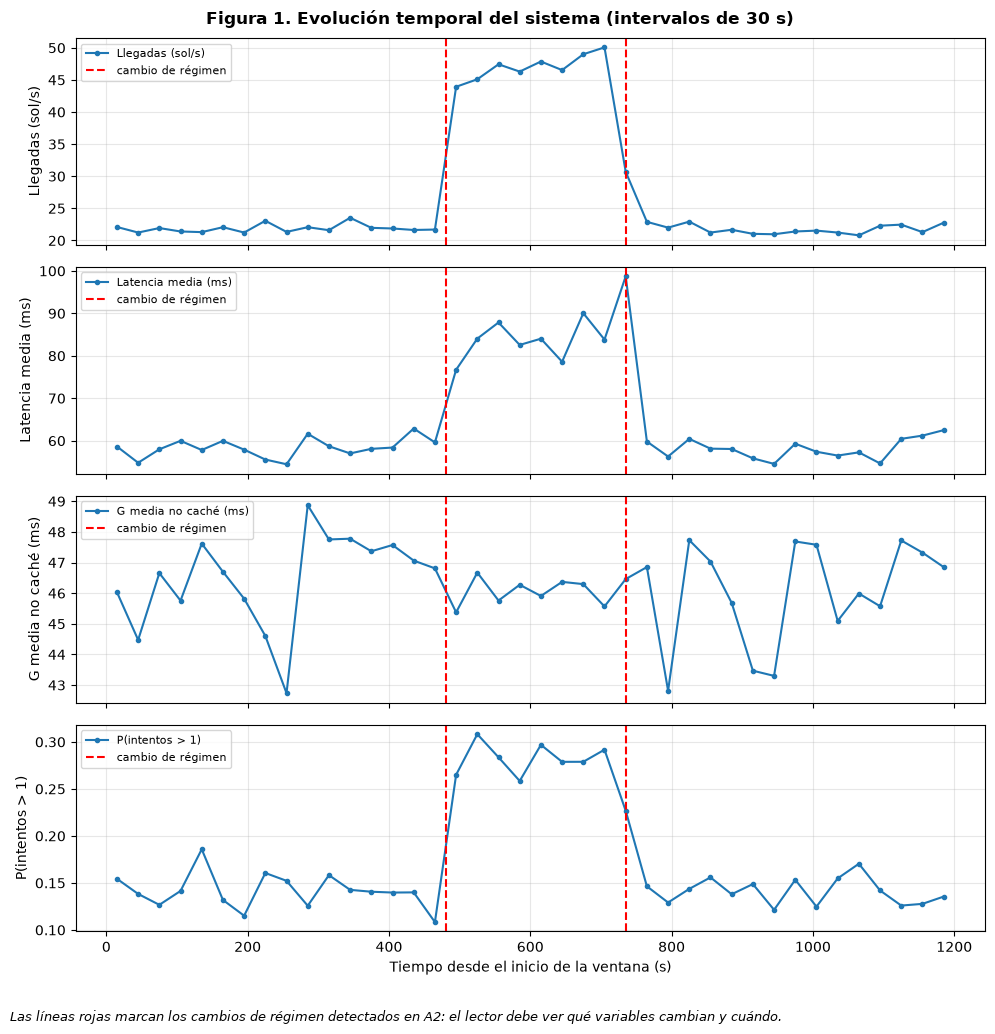

In [10]:
bordes_30 = np.arange(0, 1230, 30)
tramo_30 = pd.cut(limpio["t_llegada_s"], bordes_30, right=False)
serie = limpio.groupby(tramo_30, observed=False).agg(latencia=("latencia_ms", "mean"),
                                                    reintento=("intentos", lambda v: (v > 1).mean()))
serie["gpu"] = limpio[limpio["cache_hit"] == 0].groupby(tramo_30, observed=False)["gpu_ms"].mean()
serie["llegadas"] = np.histogram(llegadas["t_llegada_s"], bordes_30)[0] / 30
t_centro = bordes_30[:-1] + 15

fig, ejes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
columnas = [("llegadas", "Llegadas (sol/s)"), ("latencia", "Latencia media (ms)"),
            ("gpu", "G media no caché (ms)"), ("reintento", "P(intentos > 1)")]
for ax, (col, etiqueta) in zip(ejes, columnas):
    ax.plot(t_centro, serie[col], "o-", ms=3, label=etiqueta)
    for i, t_c in enumerate(CAMBIOS):
        ax.axvline(t_c, color="red", ls="--", label="cambio de régimen" if i == 0 else None)
    ax.set_ylabel(etiqueta)
    ax.legend(fontsize=8, loc="upper left")
ejes[-1].set_xlabel("Tiempo desde el inicio de la ventana (s)")
guardar_figura(fig, 1, "Evolución temporal del sistema (intervalos de 30 s)",
               "Las líneas rojas marcan los cambios de régimen detectados en A2: el lector debe ver qué variables cambian y cuándo.")

# Parte B — Llegadas, fallos y reintentos (régimen estable)

## B1 — Proceso de llegadas
**Modelo:** proceso de Poisson de tasa λ (muchos clientes independientes). Implica: tiempos entre llegadas
Exp(λ) y conteos por segundo Poisson(λ).

**Estimación:** $\hat\lambda=n/T$. **IC exacto** (relación Poisson–χ²):
$\left[\chi^2_{\alpha/2}(2n)/2T,\ \chi^2_{1-\alpha/2}(2n+2)/2T\right]$.

**Validación (dos vías):** (1) KS de los tiempos entre llegadas contra Exp(λ̂); (2) χ² de bondad de ajuste de los
conteos por segundo contra Poisson(λ̂).

In [11]:
n_lleg = len(t_est)
lam = n_lleg / T_EST
mostrar_ic("λ (sol/s)", lam, stats.chi2.ppf(ALPHA / 2, 2 * n_lleg) / (2 * T_EST),
           stats.chi2.ppf(1 - ALPHA / 2, 2 * n_lleg + 2) / (2 * T_EST), "exacto, χ²")

# Vía 1: tiempos entre llegadas vs exponencial
entre = np.diff(np.sort(t_est))
print(f"Vía 1 — KS vs Exp(λ̂): p = {stats.kstest(entre, 'expon', args=(0, 1 / lam)).pvalue:.3f} "
      f"(media {entre.mean()*1000:.1f} ms, CV = {entre.std() / entre.mean():.3f}; exponencial: CV = 1)")

# Vía 2: conteos por segundo vs Poisson (se agrupan las colas para que cada esperado sea >= 5)
conteos_1s = np.histogram(t_est, np.arange(INI_EST, FIN_EST - 1 + 1e-9, 1.0))[0]
k_lo, k_hi = int(stats.poisson.ppf(0.01, lam)), int(stats.poisson.ppf(0.99, lam))
obs = [np.sum(conteos_1s <= k_lo)] + [np.sum(conteos_1s == k) for k in range(k_lo + 1, k_hi)] + [np.sum(conteos_1s >= k_hi)]
prob = [stats.poisson.cdf(k_lo, lam)] + [stats.poisson.pmf(k, lam) for k in range(k_lo + 1, k_hi)] + [stats.poisson.sf(k_hi - 1, lam)]
esp = np.array(prob) * len(conteos_1s)
chi2_b1 = np.sum((np.array(obs) - esp)**2 / esp)
print(f"Vía 2 — χ² conteos por segundo vs Poisson: χ² = {chi2_b1:.1f}, gl = {len(obs) - 2}, "
      f"p = {stats.chi2.sf(chi2_b1, len(obs) - 2):.3f}; var/media = {conteos_1s.var() / conteos_1s.mean():.3f}")

λ (sol/s): 21.8889  IC 99% [21.3250, 22.4634]  (exacto, χ²)
Vía 1 — KS vs Exp(λ̂): p = 0.680 (media 45.7 ms, CV = 0.985; exponencial: CV = 1)
Vía 2 — χ² conteos por segundo vs Poisson: χ² = 24.6, gl = 20, p = 0.216; var/media = 0.879


## B2 — Bloques de 100 solicitudes
Si cada solicitud requiere más de un intento con probabilidad p, el número por bloque es $X\sim\text{Bin}(100,p)$:
media $100p$ y varianza $100p(1-p)$. Se estima p en el régimen estable y se contrasta con los bloques de cada
régimen. Índice de dispersión $D=s^2/[100\hat p(1-\hat p)]$: bajo el modelo, $(m-1)D\sim\chi^2_{m-1}$.

In [12]:
p_reint = (estable["intentos"] > 1).mean()
bloques = limpio.reset_index(drop=True)
bloques["bloque"] = bloques.index // 100
por_bloque = bloques.groupby("bloque").agg(x=("intentos", lambda v: (v > 1).sum()), n=("intentos", "size"),
                                           regimen=("regimen", lambda v: v.iloc[0] if v.nunique() == 1 else "mixto"))
por_bloque = por_bloque[(por_bloque["n"] == 100) & (por_bloque["regimen"] != "mixto")]

filas_b2 = []
for reg, g in por_bloque.groupby("regimen"):
    m, D = len(g), g["x"].var() / (100 * p_reint * (1 - p_reint))
    filas_b2.append({"régimen": reg, "bloques": m, "media obs": g["x"].mean(), "media modelo": 100 * p_reint,
                     "var obs": g["x"].var(), "var modelo": 100 * p_reint * (1 - p_reint), "D": D,
                     "p (dispersión)": 2 * min(stats.chi2.cdf((m - 1) * D, m - 1), stats.chi2.sf((m - 1) * D, m - 1))})
display(pd.DataFrame(filas_b2))
mostrar_ic("p (P(intentos > 1), estable)", *ic_wilson((estable["intentos"] > 1).sum(), len(estable)), "Wilson")
# Evidencia de la discrepancia: p estimada por separado en cada régimen
por_reg = limpio.groupby("regimen")["intentos"].agg(x=lambda v: (v > 1).sum(), n="size")
print(f"P(intentos > 1) por régimen, IC {NIVEL:.0%} de Wilson:")
display(pd.DataFrame([ic_wilson(f["x"], f["n"]) for _, f in por_reg.iterrows()],
                     index=por_reg.index, columns=["p", "inf", "sup"]))

,régimen,bloques,media obs,media modelo,var obs,var modelo,D,p (dispersión)
0,R1,104,14.1538,14.3589,13.9373,12.2971,1.1334,3.3524e-01
1,R2,117,28.3419,14.3589,20.9856,12.2971,1.7065,6.5018e-06
2,R3,99,14.1515,14.3589,13.8850,12.2971,1.1291,3.6029e-01


p (P(intentos > 1), estable): 0.1436  IC 99% [0.1347, 0.1530]  (Wilson)
P(intentos > 1) por régimen, IC 99% de Wilson:


,p,inf,sup
regimen,,,
R1,0.1414,0.1328,0.1504
R2,0.2821,0.2715,0.2928
R3,0.1415,0.1327,0.1507


**Lectura:** en los regímenes normales la media y la varianza coinciden con la binomial. En el régimen anómalo la
media observada se aleja porque **p cambió** (sus IC no se solapan con el del régimen estable, ver A2): el modelo con
el p del régimen estable no le sirve.

## B3 — Modelo de `intentos` y su estimador de máxima verosimilitud
Cada intento falla con probabilidad q, independientemente; el SDK abandona tras 3 fallos (geométrica **censurada
en 3**). Cada solicitud aporta $q^{f}(1-q)^{e}$ con $f$ = intentos fallidos y $e$ = 1 si tuvo éxito:

| caso | probabilidad |
|---|---|
| 1 intento | $1-q$ |
| 2 intentos | $q(1-q)$ |
| 3 intentos con éxito | $q^2(1-q)$ |
| 3 intentos, abandono | $q^3$ |

$\ell(q)=F\log q+E\log(1-q)$ con $F=\sum(\text{intentos}-\text{exito})$, $E=\sum\text{exito}$.
$\ell'(q)=0\Rightarrow\boxed{\hat q=F/(F+E)}$ = fallos totales / intentos totales.
$\text{EE}(\hat q)=\sqrt{\hat q(1-\hat q)/\sum\text{intentos}}$.

**Estimador inmediato:** si se ignora la censura, $E[I]=1/(1-q)$ ⇒ $\tilde q=1-1/\bar I$. Pero con censura
$E[I]=1+q+q^2$, así que $\tilde q$ está sesgado. Se comprueba por simulación con $q=\hat q$.

In [13]:
F = (estable["intentos"] - estable["exito"]).sum()
I_total = estable["intentos"].sum()
q_hat = F / I_total
ee_q = np.sqrt(q_hat * (1 - q_hat) / I_total)
mostrar_ic("q (EMV)", q_hat, q_hat - Z * ee_q, q_hat + Z * ee_q, "Wald")

# Simulación: 5000 muestras del mismo tamaño generadas con q = q_hat
n = len(estable)
probs = [1 - q_hat, q_hat * (1 - q_hat), q_hat**2 * (1 - q_hat), q_hat**3]
muestras = rng.multinomial(n, probs, size=5000)                   # conteos de los 4 casos
fallos = muestras[:, 1] + 2 * muestras[:, 2] + 3 * muestras[:, 3]
intentos = muestras[:, 0] + 2 * muestras[:, 1] + 3 * (muestras[:, 2] + muestras[:, 3])
q_emv, q_ingenuo = fallos / intentos, 1 - n / intentos             # 1 - 1/promedio = 1 - n/total
display(pd.DataFrame({"sesgo": [q_emv.mean() - q_hat, q_ingenuo.mean() - q_hat],
                      "desv. est.": [q_emv.std(), q_ingenuo.std()],
                      "RECM": [np.sqrt(np.mean((q_emv - q_hat)**2)), np.sqrt(np.mean((q_ingenuo - q_hat)**2))]},
                     index=["EMV", "ingenuo 1 − 1/Ī"]))

q (EMV): 0.1440  IC 99% [0.1356, 0.1525]  (Wald)


,sesgo,desv. est.,RECM
EMV,-3.5961e-06,0.0033,0.0033
ingenuo 1 − 1/Ī,-2.5704e-03,0.0032,0.0041


**Lectura:** el ingenuo tiene un sesgo que no desaparece al crecer n (su límite es $1-1/(1+q+q^2)\neq q$): no es
adecuado. El EMV es prácticamente insesgado.

## B4 — Al menos k solicitudes con reintento en 10 s
Las llegadas son Poisson(λ) y cada una, de forma independiente, requiere más de un intento con probabilidad p.
Por la **propiedad de adelgazamiento** del proceso de Poisson, las que reintentan forman un Poisson(λp); por
**estacionariedad**, en 10 s su número es $X\sim\text{Poisson}(\mu)$, $\mu=10\lambda p$.

In [14]:
mu_hat = 10 * lam * p_reint
k = int(np.ceil(mu_hat)) + R_DESPL
p_analitica = stats.poisson.sf(k - 1, mu_hat)                     # P(X >= k) = 1 - P(X <= k-1)
llegan = rng.poisson(10 * lam, 100000)                            # llegadas en 100 000 ventanas de 10 s
x_sim = rng.binomial(llegan, p_reint)                             # cuántas de ellas reintentan
print(f"μ̂ = {mu_hat:.3f}, k = ⌈μ̂⌉ + r = {k}")
print(f"P(X ≥ {k}): analítica = {p_analitica:.4f}")
mostrar_ic(f"P(X ≥ {k}) Montecarlo", *ic_wilson(np.sum(x_sim >= k), len(x_sim)), "Wilson, 100 000 réplicas")

μ̂ = 31.430, k = ⌈μ̂⌉ + r = 37
P(X ≥ 37): analítica = 0.1812
P(X ≥ 37) Montecarlo: 0.1818  IC 99% [0.1786, 0.1849]  (Wilson, 100 000 réplicas)


# Parte C — Tiempo de cómputo y tiempo de red

## C1 — Distribución de G (todas las solicitudes)
G es **mixta**: vale exactamente 0 si hubo caché (probabilidad $p_c>0$) y es continua si no. Con $F_c$ la FDA de
G | no caché:
$$F_G(x)=0\ (x<0),\qquad F_G(x)=p_c+(1-p_c)F_c(x)\ (x\ge0).$$
Con $\mu_c,\sigma_c^2$ la media y varianza de G | no caché:
$E[G]=(1-p_c)\mu_c$ y $\text{Var}(G)=(1-p_c)\sigma_c^2+p_c(1-p_c)\mu_c^2$.

In [15]:
g_todas = estable["gpu_ms"].to_numpy()
g_nc = nc_est["gpu_ms"].to_numpy()
p_c = estable["cache_hit"].mean()
mu_c, var_c = g_nc.mean(), g_nc.var()
print(f"p_c = {p_c:.4f}, μ_c = {mu_c:.3f} ms, σ²_c = {var_c:.3f} ms²")
print(f"E[G]:   fórmula = {(1 - p_c) * mu_c:.3f} | muestral = {g_todas.mean():.3f}")
print(f"Var(G): fórmula = {(1 - p_c) * var_c + p_c * (1 - p_c) * mu_c**2:.3f} | muestral = {g_todas.var():.3f}")

p_c = 0.3159, μ_c = 46.478 ms, σ²_c = 1084.249 ms²
E[G]:   fórmula = 31.798 | muestral = 31.798
Var(G): fórmula = 1208.590 | muestral = 1208.590


## C2 — Máxima verosimilitud para la parte continua (modelo Gamma)
Log-verosimilitud de Gamma(k, θ):
$\ell(k,\theta)=-n\log\Gamma(k)-nk\log\theta+(k-1)\sum\log x_i-\sum x_i/\theta$.
Se minimiza $-\ell$ con `optimize.minimize` sobre $(\log k,\log\theta)$, para que ambos sean positivos.
**Otro método:** momentos, $k=\bar x^2/s^2$, $\theta=s^2/\bar x$.

In [16]:
def menos_logver(param_log, x):
    k, theta = np.exp(param_log)
    n = len(x)
    logver = -n * gammaln(k) - n * k * np.log(theta) + (k - 1) * np.sum(np.log(x)) - np.sum(x) / theta
    return -logver


k_mom, theta_mom = mu_c**2 / var_c, var_c / mu_c                  # método de momentos
res = optimize.minimize(menos_logver, x0=np.log([k_mom, theta_mom]), args=(g_nc,), method="Nelder-Mead")
k_emv, theta_emv = np.exp(res.x)
print(f"EMV:      k = {k_emv:.3f}, θ = {theta_emv:.3f}")
print(f"Momentos: k = {k_mom:.3f}, θ = {theta_mom:.3f}")
print(f"KS contra Gamma EMV: D = {stats.kstest(g_nc, 'gamma', args=(k_emv, 0, theta_emv)).statistic:.4f}, "
      f"p = {stats.kstest(g_nc, 'gamma', args=(k_emv, 0, theta_emv)).pvalue:.3g}")
print("Media de G (no caché) por clase de tamaño:",
      nc_est.groupby(pd.cut(nc_est["tam_kb"], [0, T1_KB, T2_KB, np.inf], right=False,
                             labels=["pequeña", "mediana", "grande"]), observed=True)["gpu_ms"].mean().round(1).to_dict())

EMV:      k = 2.420, θ = 19.207
Momentos: k = 1.992, θ = 23.328
KS contra Gamma EMV: D = 0.0372, p = 1.78e-08
Media de G (no caché) por clase de tamaño: {'pequeña': 22.2, 'mediana': 41.9, 'grande': 84.0}


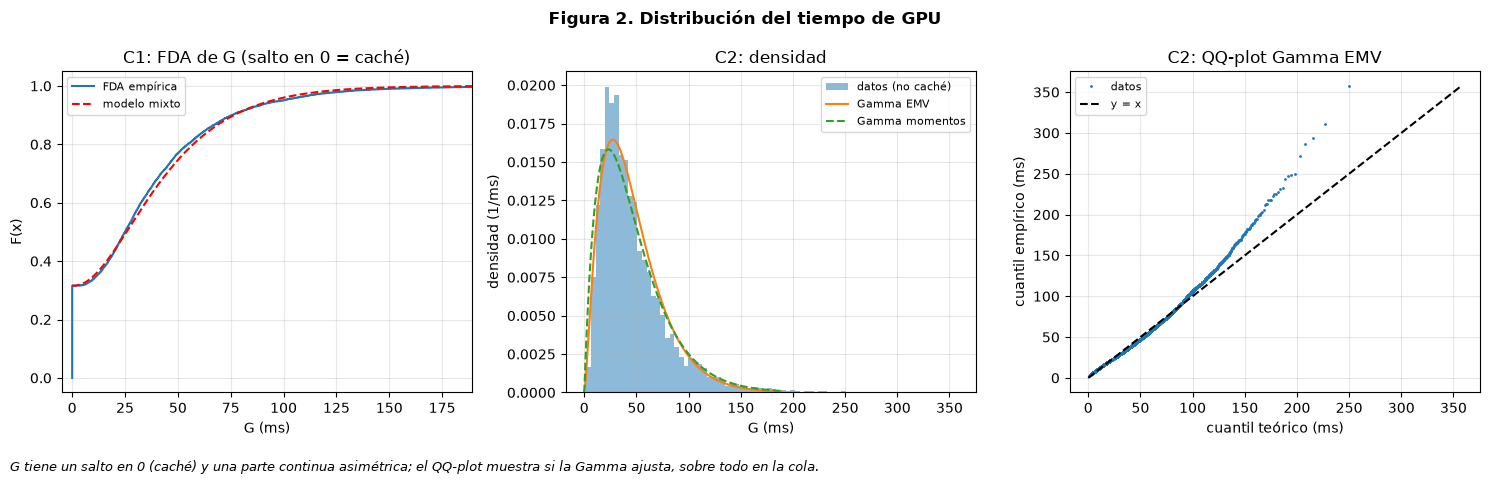

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
x = np.linspace(0, np.quantile(g_nc, 0.995), 300)
ejes[0].step(np.sort(g_todas), np.arange(1, len(g_todas) + 1) / len(g_todas), label="FDA empírica")
ejes[0].plot(x, p_c + (1 - p_c) * stats.gamma.cdf(x, k_emv, scale=theta_emv), "r--", label="modelo mixto")
ejes[0].set(title="C1: FDA de G (salto en 0 = caché)", xlabel="G (ms)", ylabel="F(x)", xlim=(-5, x.max()))
ejes[1].hist(g_nc, bins=80, density=True, alpha=0.5, label="datos (no caché)")
ejes[1].plot(x, stats.gamma.pdf(x, k_emv, scale=theta_emv), label="Gamma EMV")
ejes[1].plot(x, stats.gamma.pdf(x, k_mom, scale=theta_mom), "--", label="Gamma momentos")
ejes[1].set(title="C2: densidad", xlabel="G (ms)", ylabel="densidad (1/ms)")
cuantiles = stats.gamma.ppf((np.arange(len(g_nc)) + 0.5) / len(g_nc), k_emv, scale=theta_emv)
ejes[2].plot(cuantiles, np.sort(g_nc), ".", ms=2, label="datos")
ejes[2].plot([0, g_nc.max()], [0, g_nc.max()], "k--", label="y = x")
ejes[2].set(title="C2: QQ-plot Gamma EMV", xlabel="cuantil teórico (ms)", ylabel="cuantil empírico (ms)")
for ax in ejes:
    ax.legend(fontsize=8)
guardar_figura(fig, 2, "Distribución del tiempo de GPU",
               "G tiene un salto en 0 (caché) y una parte continua asimétrica; el QQ-plot muestra si la Gamma ajusta, "
               "sobre todo en la cola.")

**Discusión:** el tiempo de GPU depende del tamaño de la imagen (medias muy distintas por clase). El modelo
marginal mezcla tamaños distintos, por eso puede fallar en la cola. En el simulador (Parte G) se usa G
condicionado al tamaño (Parte D3).

## C3 — ¿`red_ms` es normal?
Criterios: (1) asimetría y curtosis (la normal tiene 0 y 0); (2) prueba de D'Agostino; (3) QQ-plot y
comparación de probabilidades de cola.

In [18]:
red = estable["red_ms"].to_numpy()
media_red, sd_red = red.mean(), red.std()
p_normal = stats.normaltest(red).pvalue
print(f"asimetría = {stats.skew(red):.3f}, curtosis = {stats.kurtosis(red):.3f}, D'Agostino p = {p_normal:.3g}")
print("Conclusión:", "no se rechaza la normalidad" if p_normal > ALPHA else "se rechaza la normalidad",
      "(comparar además las probabilidades de cola de la tabla siguiente)")

xs = [round(media_red + c * sd_red) for c in (2, 3, 3.5)]
display(pd.DataFrame({"x (ms)": xs,
                      "P(red > x) empírica": [np.mean(red > x) for x in xs],
                      "P(red > x) normal": [stats.norm.sf(x, media_red, sd_red) for x in xs]}))

boot = [np.quantile(rng.choice(red, len(red)), 0.999) for _ in range(1000)]
mostrar_ic("Percentil 99,9 % de red (ms)", np.quantile(red, 0.999), *np.quantile(boot, [ALPHA / 2, 1 - ALPHA / 2]),
           "bootstrap, 1000 réplicas")

asimetría = 0.027, curtosis = -0.042, D'Agostino p = 0.399
Conclusión: no se rechaza la normalidad (comparar además las probabilidades de cola de la tabla siguiente)


,x (ms),P(red > x) empírica,P(red > x) normal
0,31,0.0179,0.0169
1,34,0.0017,0.0016
2,36,0.0001,0.0002


Percentil 99,9 % de red (ms): 34.6224  IC 99% [33.7798, 35.2000]  (bootstrap, 1000 réplicas)


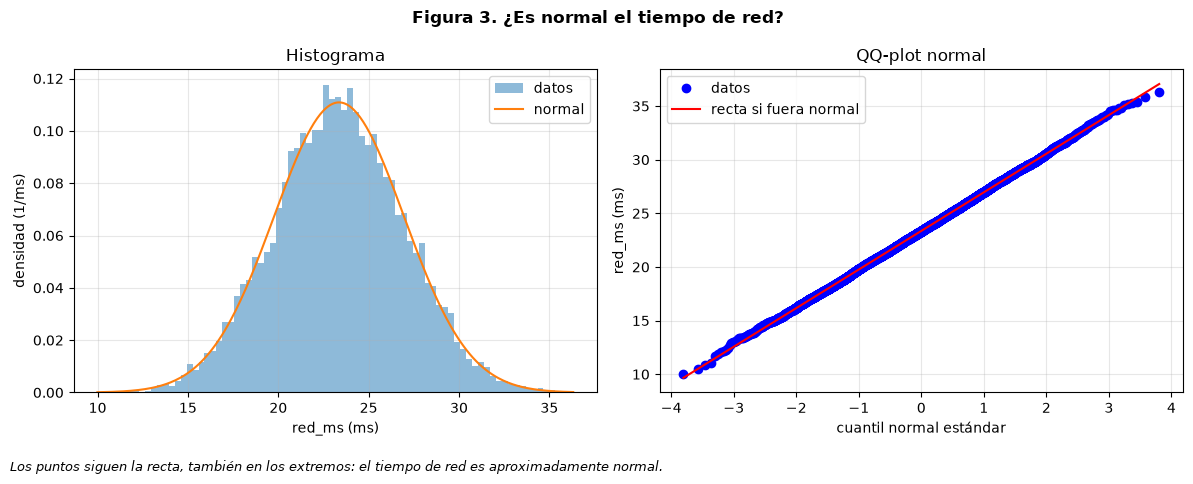

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
xr = np.linspace(red.min(), red.max(), 300)
ejes[0].hist(red, bins=80, density=True, alpha=0.5, label="datos")
ejes[0].plot(xr, stats.norm.pdf(xr, media_red, sd_red), label="normal")
ejes[0].set(xlabel="red_ms (ms)", ylabel="densidad (1/ms)", title="Histograma")
ejes[0].legend()
stats.probplot(red, dist="norm", plot=ejes[1])
ejes[1].get_lines()[0].set_label("datos")
ejes[1].get_lines()[1].set_label("recta si fuera normal")
ejes[1].legend()
ejes[1].set(title="QQ-plot normal", xlabel="cuantil normal estándar", ylabel="red_ms (ms)")
guardar_figura(fig, 3, "¿Es normal el tiempo de red?",
               "Los puntos siguen la recta, también en los extremos: el tiempo de red es aproximadamente normal."
               if p_normal > ALPHA else
               "El QQ-plot se curva en los extremos: la normal no describe la cola del tiempo de red.")

## C4 — Tiempo total de N solicitudes no cacheadas
$T_N=\sum_{i=1}^N G_i$. Dos aproximaciones:
1. **TLC:** $T_N\approx\mathcal N(N\mu,N\sigma^2)$ ⇒ $P(T_N>N(\hat m+15))\approx1-\Phi(15\sqrt N/\sigma)$.
2. **Gamma exacta:** si $G_i\sim\text{Gamma}(k,\theta)$, la suma es $\text{Gamma}(Nk,\theta)$.

Se comparan con una simulación (sumas de N valores tomados al azar de los datos).

In [20]:
m_hat, s_hat = g_nc.mean(), g_nc.std()
umbral = N_CONSEC * (m_hat + 15)
p_tlc = stats.norm.sf(15 * np.sqrt(N_CONSEC) / s_hat)
p_gamma = stats.gamma.sf(umbral, N_CONSEC * k_emv, scale=theta_emv)
sumas = rng.choice(g_nc, size=(100000, N_CONSEC)).sum(axis=1)
p_sim = np.mean(sumas > umbral)
print(f"N = {N_CONSEC}, umbral = {umbral:.1f} ms")
print(f"TLC = {p_tlc:.4f} | Gamma exacta = {p_gamma:.4f} | simulación = {p_sim:.4f}")
print("Más cercana a la simulación:", "TLC" if abs(p_tlc - p_sim) < abs(p_gamma - p_sim) else "Gamma exacta")

N = 20, umbral = 1229.6 ms
TLC = 0.0208 | Gamma exacta = 0.0184 | simulación = 0.0309
Más cercana a la simulación: TLC


**¿Cuál es preferible?** La que más se acerque a la simulación. El TLC ignora la asimetría de G (con N pequeño la
suma sigue siendo asimétrica) y la Gamma exacta solo es correcta si G realmente es Gamma (ver el QQ-plot de C2).

# Parte D — Dependencias y esperanza condicional

## D1 — Conjunta de (clase de tamaño, `cache_hit`)
Conjunta = proporción de cada combinación; marginales = totales; condicional $P(\text{caché}\mid\text{clase})$.
Si son independientes, la condicional es igual en todas las clases. Evidencia: prueba χ² de independencia e IC
de Wilson de cada condicional.

In [21]:
estable["clase"] = pd.cut(estable["tam_kb"], [0, T1_KB, T2_KB, np.inf], right=False,
                          labels=["pequeña", "mediana", "grande"])
conjunta = pd.crosstab(estable["clase"], estable["cache_hit"], normalize=True, margins=True)
print("Conjunta y marginales:"); display(conjunta.round(4))

conteos_d1 = pd.crosstab(estable["clase"], estable["cache_hit"])
cond = pd.DataFrame([ic_wilson(fila[1], fila.sum()) for _, fila in conteos_d1.iterrows()],
                    index=conteos_d1.index, columns=["P(caché | clase)", "IC inf", "IC sup"])
print(f"Condicionales P(caché | clase), IC {NIVEL:.0%} de Wilson:"); display(cond)
chi2_d1, p_d1, _, _ = stats.chi2_contingency(conteos_d1)
print(f"χ² de independencia = {chi2_d1:.1f}, p = {p_d1:.2e} ->",
      "NO son independientes" if p_d1 < ALPHA else "no hay evidencia contra la independencia")

Conjunta y marginales:


cache_hit,0,1,All
clase,,,
pequeña,0.0882,0.0909,0.1791
mediana,0.4801,0.2063,0.6864
grande,0.1158,0.0186,0.1345
All,0.6841,0.3159,1.0000


Condicionales P(caché | clase), IC 99% de Wilson:


,P(caché | clase),IC inf,IC sup
clase,,,
pequeña,0.5077,0.4770,0.5384
mediana,0.3005,0.2863,0.3151
grande,0.1386,0.1159,0.1650


χ² de independencia = 496.1, p = 1.85e-108 -> NO son independientes


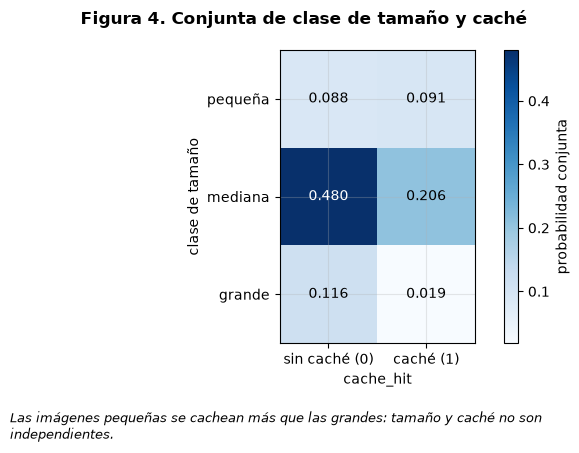

In [22]:
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(conjunta.iloc[:3, :2].to_numpy(), cmap="Blues")
for i in range(3):
    for j in range(2):
        ax.text(j, i, f"{conjunta.iloc[i, j]:.3f}", ha="center", va="center",
                color="white" if conjunta.iloc[i, j] > 0.3 else "black")
ax.set_xticks([0, 1], ["sin caché (0)", "caché (1)"])
ax.set_yticks([0, 1, 2], conjunta.index[:3])
ax.set(xlabel="cache_hit", ylabel="clase de tamaño")
fig.colorbar(im, label="probabilidad conjunta")
guardar_figura(fig, 4, "Conjunta de clase de tamaño y caché",
               "Las imágenes pequeñas se cachean más que las grandes: tamaño y caché no son independientes.")

## D2 — Esperanza condicional, esperanza total y varianza total
- $E[G\mid\text{clase},\text{no caché}]$: media por clase.
- $E[G\mid\text{tam\_kb}]$ no paramétrica: media de G en cada decil de tamaño.
- **Esperanza total:** $E[G]=\sum P(\text{clase})\,E[G\mid\text{clase}]$.
- **Varianza total:** $\text{Var}(G)=E[\text{Var}(G\mid\text{clase})]+\text{Var}(E[G\mid\text{clase}])$; la fracción
  explicada por la clase es $\text{Var}(E[G\mid\text{clase}])/\text{Var}(G)$.

In [23]:
nc_est = estable[estable["cache_hit"] == 0]
print("E[G | clase, no caché]:", nc_est.groupby("clase", observed=True)["gpu_ms"].mean().round(2).to_dict())
deciles = estable.groupby(pd.qcut(estable["tam_kb"], 10), observed=True)["gpu_ms"].mean()
print("E[G | tam_kb] por decil de tamaño:"); display(deciles.round(2))

grupo = estable.groupby("clase", observed=True)["gpu_ms"]
P_cl, E_cl, V_cl = grupo.size() / len(estable), grupo.mean(), grupo.var(ddof=0)
E_G, var_G = estable["gpu_ms"].mean(), estable["gpu_ms"].var(ddof=0)
var_dentro, var_entre = np.sum(P_cl * V_cl), np.sum(P_cl * (E_cl - E_G)**2)
print(f"Esperanza total: Σ P·E[G|clase] = {np.sum(P_cl * E_cl):.4f} | E[G] = {E_G:.4f}")
print(f"Varianza total: {var_dentro:.2f} + {var_entre:.2f} = {var_dentro + var_entre:.2f} | Var(G) = {var_G:.2f}")
print(f"Fracción de Var(G) explicada por la clase: {var_entre / var_G:.3f}")

E[G | clase, no caché]: {'pequeña': 22.17, 'mediana': 41.88, 'grande': 84.04}
E[G | tam_kb] por decil de tamaño:


tam_kb
(2.209, 62.693]        9.65
(62.693, 97.086]      13.72
(97.086, 129.746]     21.15
(129.746, 165.392]    22.38
(165.392, 202.465]    26.29
(202.465, 243.098]    28.90
(243.098, 290.883]    32.28
(290.883, 360.168]    38.78
(360.168, 472.808]    48.21
(472.808, 1382.17]    76.59
Name: gpu_ms, dtype: float64

Esperanza total: Σ P·E[G|clase] = 31.7979 | E[G] = 31.7979
Varianza total: 904.59 + 304.00 = 1208.59 | Var(G) = 1208.59
Fracción de Var(G) explicada por la clase: 0.252


## D3 — Modelo lineal $E[G\mid\text{tam},\text{no caché}]=\beta_0+\beta_1\,\text{tam}$
Ecuaciones normales: $X^\top X\hat\beta=X^\top y$. $\text{Cov}(\hat\beta)=\hat\sigma^2(X^\top X)^{-1}$,
$\hat\sigma^2=\text{SCE}/(n-2)$.

**Supuesto a revisar:** varianza constante de los residuos. Si G | tam es Gamma (C2), su varianza es
$\mu^2/k$: crece con la media. **Corrección:** mínimos cuadrados ponderados con pesos $w=1/\hat\mu^2$:
$\hat\beta_W=(X^\top WX)^{-1}X^\top Wy$, iterando porque $\hat\mu$ depende de $\hat\beta$.

In [24]:
def minimos_cuadrados(tam, g, pesos=None):
    X = np.column_stack([np.ones(len(tam)), tam])
    w = np.ones(len(g)) if pesos is None else pesos
    XtWX = X.T @ (X * w[:, None])
    beta = np.linalg.solve(XtWX, X.T @ (w * g))                    # resuelve el sistema matricial
    resid = g - X @ beta
    sigma2 = np.sum(w * resid**2) / (len(g) - 2)
    ee = np.sqrt(np.diag(sigma2 * np.linalg.inv(XtWX)))
    return beta, ee, sigma2


tam_nc, g_nc = nc_est["tam_kb"].to_numpy(), nc_est["gpu_ms"].to_numpy()
t_crit = stats.t.ppf(1 - ALPHA / 2, len(g_nc) - 2)
beta_mco, ee_mco, _ = minimos_cuadrados(tam_nc, g_nc)
for j, nombre in enumerate(["β0 (ms)", "β1 (ms/KB)"]):
    mostrar_ic(f"MCO {nombre}", beta_mco[j], beta_mco[j] - t_crit * ee_mco[j], beta_mco[j] + t_crit * ee_mco[j], "t")
print("Verificación numérica con np.polyfit (β0, β1):", np.round(np.polyfit(tam_nc, g_nc, 1)[::-1], 5))

# Residuos: ¿la varianza crece con el valor ajustado?
ajustado = beta_mco[0] + beta_mco[1] * tam_nc
resid = g_nc - ajustado
quintil = pd.qcut(ajustado, 5)
print("Desviación de los residuos por quintil del valor ajustado:",
      pd.Series(resid).groupby(quintil, observed=True).std().round(1).tolist())

# Corrección: pesos 1/μ², iterando hasta que β no cambie
beta_w = beta_mco
for _ in range(20):
    beta_w, ee_w, phi = minimos_cuadrados(tam_nc, g_nc, 1 / (beta_w[0] + beta_w[1] * tam_nc)**2)
for j, nombre in enumerate(["β0 (ms)", "β1 (ms/KB)"]):
    mostrar_ic(f"MCP {nombre}", beta_w[j], beta_w[j] - t_crit * ee_w[j], beta_w[j] + t_crit * ee_w[j], "t, pesos 1/μ²")
k_gamma = 1 / phi                                                  # forma Gamma implícita (se usa en G)
print(f"Forma Gamma implícita k = 1/φ = {k_gamma:.3f}")

MCO β0 (ms): 15.7766  IC 99% [14.3646, 17.1886]  (t)
MCO β1 (ms/KB): 0.1174  IC 99% [0.1129, 0.1218]  (t)
Verificación numérica con np.polyfit (β0, β1): [15.7766   0.11738]
Desviación de los residuos por quintil del valor ajustado: [12.7, 16.8, 19.9, 27.3, 40.3]
MCP β0 (ms): 15.7790  IC 99% [14.8563, 16.7016]  (t, pesos 1/μ²)
MCP β1 (ms/KB): 0.1174  IC 99% [0.1125, 0.1222]  (t, pesos 1/μ²)
Forma Gamma implícita k = 1/φ = 3.994


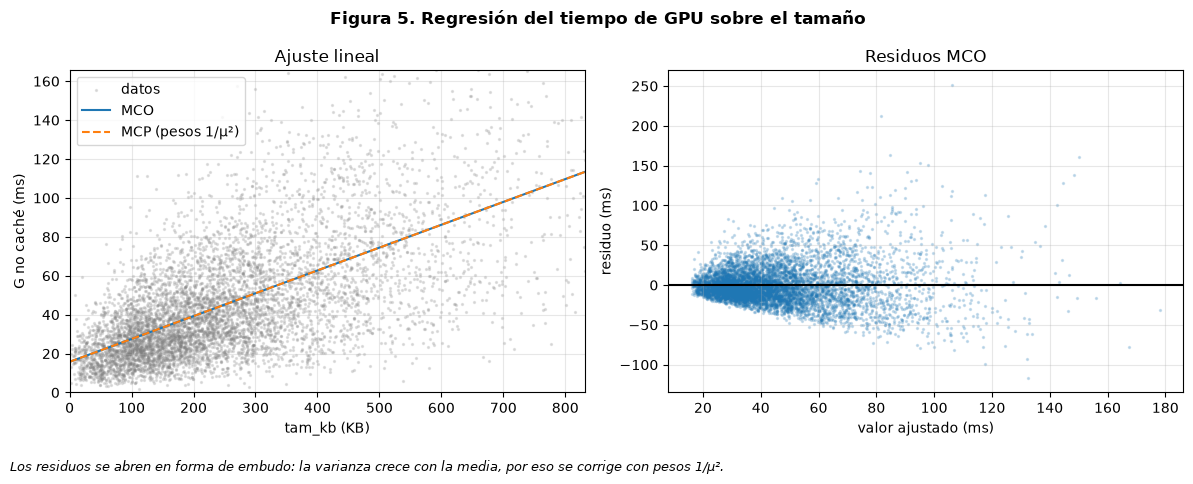

In [25]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
xs = np.linspace(0, np.quantile(tam_nc, 0.99), 100)
ejes[0].scatter(tam_nc, g_nc, s=2, alpha=0.2, color="gray", label="datos")
ejes[0].plot(xs, beta_mco[0] + beta_mco[1] * xs, label="MCO")
ejes[0].plot(xs, beta_w[0] + beta_w[1] * xs, "--", label="MCP (pesos 1/μ²)")
ejes[0].set(xlabel="tam_kb (KB)", ylabel="G no caché (ms)", title="Ajuste lineal",
            xlim=(0, xs.max()), ylim=(0, np.quantile(g_nc, 0.99)))
ejes[0].legend()
ejes[1].scatter(ajustado, resid, s=2, alpha=0.2)
ejes[1].axhline(0, color="k")
ejes[1].set(xlabel="valor ajustado (ms)", ylabel="residuo (ms)", title="Residuos MCO")
guardar_figura(fig, 5, "Regresión del tiempo de GPU sobre el tamaño",
               "Los residuos se abren en forma de embudo: la varianza crece con la media, por eso se corrige con pesos 1/μ².")

## D4 — Covarianza y correlación

In [26]:
cov_d4 = np.cov(tam_nc, g_nc)[0, 1]
r_d4 = np.corrcoef(tam_nc, g_nc)[0, 1]
print(f"Cov = {cov_d4:.2f} KB·ms | r = {r_d4:.4f} | r² = {r_d4**2:.4f}")
print(f"β1 de MCO = Cov/Var(tam) = {cov_d4 / np.var(tam_nc, ddof=1):.5f} (MCO: {beta_mco[1]:.5f})")

Cov = 3774.52 KB·ms | r = 0.6392 | r² = 0.4086
β1 de MCO = Cov/Var(tam) = 0.11738 (MCO: 0.11738)


**Lectura:** la pendiente de MCO es Cov/Var(tam) y su R² es r². La correlación mide solo la parte lineal de la
relación; la fracción explicada por la clase (D2) usa solo 3 grupos, por eso suele ser menor que r².

# Parte E — Monitoreo y decisión de alertas

## E1 — Sensibilidad y tasa de falsos positivos
Sensibilidad $s=P(\text{alerta}\mid\text{incidente})$; tasa de falsos positivos $f=P(\text{alerta}\mid\text{normal})$.
No dependen de la prevalencia, por eso se pueden estimar en el entorno de pruebas.

In [27]:
inc = monitoreo["incidente"] == 1
d1, d2 = monitoreo["D1"] == 1, monitoreo["D2"] == 1
reglas = {"D1": d1, "D2": d2, "D1 y D2": d1 & d2, "D1 o D2": d1 | d2}

filas_e1 = []
for nombre, alerta in reglas.items():
    s, s_inf, s_sup = ic_wilson((alerta & inc).sum(), inc.sum())
    f, f_inf, f_sup = ic_wilson((alerta & ~inc).sum(), (~inc).sum())
    filas_e1.append([nombre, s, s_inf, s_sup, f, f_inf, f_sup])
tabla_e1 = pd.DataFrame(filas_e1, columns=["regla", "s", "s inf", "s sup", "f", "f inf", "f sup"]).set_index("regla")
print(f"Intervalos al {NIVEL:.0%}, método de Wilson:")
display(tabla_e1)

Intervalos al 99%, método de Wilson:


,s,s inf,s sup,f,f inf,f sup
regla,,,,,,
D1,0.9052,0.8676,0.9330,0.0092,0.0064,0.0131
D2,0.7565,0.7059,0.8009,0.0077,0.0052,0.0114
D1 y D2,0.6877,0.6342,0.7366,0.0022,0.0011,0.0045
D1 o D2,0.9740,0.9497,0.9867,0.0146,0.0110,0.0195


## E2 — P(incidente | alerta) en producción
Teorema de Bayes con la prevalencia de producción π: $\text{VPP}=\dfrac{s\pi}{s\pi+f(1-\pi)}$.
Intervalo: se evalúa el VPP en los extremos de los IC de s y f (peor y mejor caso).

In [28]:
def vpp(s, f, prev=PI_PROD):
    return s * prev / (s * prev + f * (1 - prev))

tabla_e2 = pd.DataFrame({
    "VPP producción": vpp(tabla_e1["s"], tabla_e1["f"]),
    "inf": vpp(tabla_e1["s inf"], tabla_e1["f sup"]),
    "sup": vpp(tabla_e1["s sup"], tabla_e1["f inf"]),
    "VPP en monitoreo.csv": [(a & inc).sum() / a.sum() for a in reglas.values()],
})
print(f"Intervalo al {NIVEL:.0%}: VPP evaluado en los extremos de los IC de Wilson de s y f")
display(tabla_e2)
# Verificación por simulación (regla D1): un millón de minutos de producción
hay_inc = rng.random(1_000_000) < PI_PROD
alerta_sim = rng.random(1_000_000) < np.where(hay_inc, tabla_e1.loc["D1", "s"], tabla_e1.loc["D1", "f"])
print(f"Verificación D1: simulación {hay_inc[alerta_sim].mean():.4f} vs Bayes {tabla_e2.loc['D1', 'VPP producción']:.4f}")
print(f"Prevalencia en pruebas = {inc.mean():.3f} vs producción π = {PI_PROD}")

Intervalo al 99%: VPP evaluado en los extremos de los IC de Wilson de s y f


,VPP producción,inf,sup,VPP en monitoreo.csv
regla,,,,
D1,0.4731,0.3752,0.5705,0.9069
D2,0.4719,0.3602,0.5838,0.9065
D1 y D2,0.7398,0.5592,0.8630,0.9686
D1 o D2,0.3765,0.3071,0.4487,0.8675


Verificación D1: simulación 0.4733 vs Bayes 0.4731
Prevalencia en pruebas = 0.090 vs producción π = 0.009


**¿Por qué difieren?** En pruebas los incidentes se inyectaron con una prevalencia mucho mayor. Con π pequeño hay
muchísimos más minutos normales, así que incluso una f pequeña produce más falsas alarmas que alarmas verdaderas.

## E3 — ¿D1 y D2 son condicionalmente independientes?
Dentro de cada estado se compara $P(D_1\wedge D_2)$ con $P(D_1)P(D_2)$ y se aplica una prueba χ² a la tabla 2×2.

In [29]:
filas_e3 = []
for estado, m in [("con incidente", inc), ("sin incidente", ~inc)]:
    filas_e3.append([estado, (d1[m] & d2[m]).mean(), d1[m].mean() * d2[m].mean(),
                     stats.chi2_contingency(pd.crosstab(d1[m], d2[m]))[1]])
display(pd.DataFrame(filas_e3, columns=["estado", "P(D1 y D2)", "P(D1)·P(D2)", "p χ²"]))

# Efecto sobre E2: VPP de las reglas combinadas si se SUPONE independencia
s1, s2, f1, f2 = tabla_e1.loc["D1", "s"], tabla_e1.loc["D2", "s"], tabla_e1.loc["D1", "f"], tabla_e1.loc["D2", "f"]
display(pd.DataFrame({
    "VPP con datos (E2)": [tabla_e2.loc["D1 y D2", "VPP producción"], tabla_e2.loc["D1 o D2", "VPP producción"]],
    "VPP suponiendo independencia": [vpp(s1 * s2, f1 * f2), vpp(s1 + s2 - s1 * s2, f1 + f2 - f1 * f2)],
}, index=["D1 y D2", "D1 o D2"]))

,estado,P(D1 y D2),P(D1)·P(D2),p χ²
0,con incidente,0.6877,6.8479e-01,7.1066e-01
1,sin incidente,0.0022,7.0391e-05,4.6825e-73


,VPP con datos (E2),VPP suponiendo independencia
D1 y D2,0.7398,0.9888
D1 o D2,0.3765,0.3460


## E4 — Falsas alarmas por día
Cada minuto produce una falsa alarma con probabilidad $f(1-\pi)$; en 1440 minutos independientes
$FA\sim\text{Bin}(1440,\,f(1-\pi))$. Se exige $P(FA\le k_{máx})\ge0{,}90$.
**Incertidumbre:** P(FA ≤ k_máx) disminuye con f, así que su IC sale de evaluar en los extremos del IC de f.
Una regla cumple con seguridad si incluso con f en su extremo superior se llega a 0,90.

In [30]:
def p_cumple(f):
    return stats.binom.cdf(K_MAX, 1440, f * (1 - PI_PROD))

tabla_e4 = pd.DataFrame({
    "FA esperadas/día": 1440 * tabla_e1["f"] * (1 - PI_PROD),
    "P(FA ≤ k_máx)": p_cumple(tabla_e1["f"]),
    "inf": p_cumple(tabla_e1["f sup"]), "sup": p_cumple(tabla_e1["f inf"]),
    "sensibilidad": tabla_e1["s"],
})
tabla_e4["cumple"] = tabla_e4["inf"] >= 0.90
print(f"Intervalo al {NIVEL:.0%}: P(FA ≤ k_máx) evaluada en los extremos del IC de Wilson de f")
display(tabla_e4)
cumplen = tabla_e4[tabla_e4["cumple"]]
REGLA = cumplen["sensibilidad"].idxmax() if len(cumplen) else tabla_e4["P(FA ≤ k_máx)"].idxmax()
print("Regla recomendada:", REGLA, "(la más sensible entre las que cumplen)" if len(cumplen)
      else "(ninguna cumple; es la más cercana)")
# Verificación por simulación: 20 000 días de 1440 minutos con la regla recomendada
falsas = (rng.random((20000, 1440)) < tabla_e1.loc[REGLA, "f"] * (1 - PI_PROD)).sum(axis=1)
print(f"Verificación {REGLA}: simulación {np.mean(falsas <= K_MAX):.4f} vs binomial {tabla_e4.loc[REGLA, 'P(FA ≤ k_máx)']:.4f}")

Intervalo al 99%: P(FA ≤ k_máx) evaluada en los extremos del IC de Wilson de f


,FA esperadas/día,P(FA ≤ k_máx),inf,sup,sensibilidad,cumple
regla,,,,,,
D1,13.0633,1.0055e-02,1.7676e-04,0.1088,0.9052,False
D2,10.9732,3.7608e-02,1.1058e-03,0.2518,0.7565,False
D1 y D2,3.1352,9.0207e-01,3.7164e-01,0.9954,0.6877,False
D1 o D2,20.9014,3.2846e-05,1.2024e-07,0.0016,0.9740,False


Regla recomendada: D1 y D2 (ninguna cumple; es la más cercana)


Verificación D1 y D2: simulación 0.9024 vs binomial 0.9021


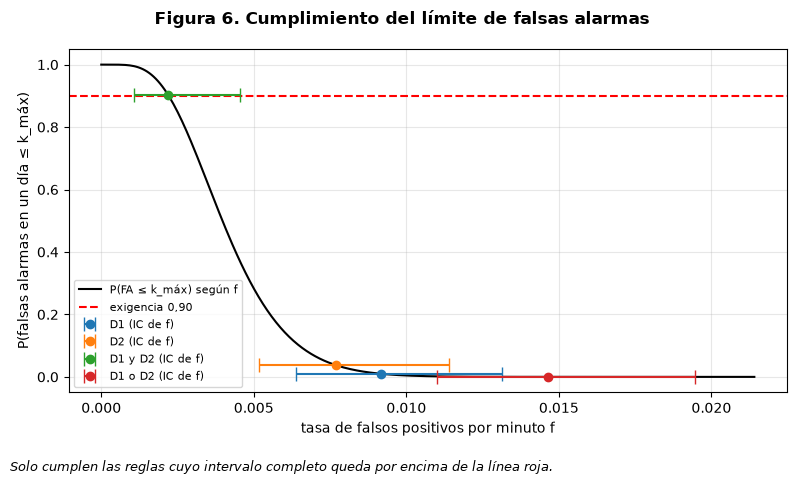

In [31]:
fig, ax = plt.subplots(figsize=(8, 4.5))
f_eje = np.linspace(0, tabla_e1["f sup"].max() * 1.1, 300)
ax.plot(f_eje, p_cumple(f_eje), "k-", label="P(FA ≤ k_máx) según f")
ax.axhline(0.90, color="red", ls="--", label="exigencia 0,90")
for nombre, fila in tabla_e1.iterrows():
    ax.errorbar(fila["f"], p_cumple(fila["f"]), xerr=[[fila["f"] - fila["f inf"]], [fila["f sup"] - fila["f"]]],
                fmt="o", capsize=5, label=f"{nombre} (IC de f)")
ax.set(xlabel="tasa de falsos positivos por minuto f", ylabel="P(falsas alarmas en un día ≤ k_máx)")
ax.legend(fontsize=8)
guardar_figura(fig, 6, "Cumplimiento del límite de falsas alarmas",
               "Solo cumplen las reglas cuyo intervalo completo queda por encima de la línea roja.")

# Parte F — Inferencia y comparación de versiones

## F1 — Distribución muestral de la media de la latencia
**Población:** las latencias válidas del régimen estable (la mejor representación del servicio en operación
normal). Se toman muestras con reemplazo, así que la media verdadera μ es conocida.
**Cobertura:** proporción de intervalos $\bar x\pm z\,s/\sqrt n$ que contienen μ.

In [32]:
poblacion = estable["latencia_ms"].to_numpy()
mu_pob, sigma_pob = poblacion.mean(), poblacion.std()
R_F1 = 5000

def medias_y_cobertura(n):
    muestras = rng.choice(poblacion, size=(R_F1, n))
    medias, desv = muestras.mean(axis=1), muestras.std(axis=1, ddof=1)
    cobertura = np.mean(np.abs(medias - mu_pob) <= Z * desv / np.sqrt(n))
    return medias, cobertura

medias_n, filas_f1 = {}, []
for n in [5, 30, 200, 2000]:
    medias_n[n], cob = medias_y_cobertura(n)
    filas_f1.append([n, medias_n[n].std(), sigma_pob / np.sqrt(n), stats.skew(medias_n[n]),
                     stats.kurtosis(medias_n[n]), cob])
display(pd.DataFrame(filas_f1, columns=["n", "desv. de x̄", "σ/√n", "asimetría", "curtosis", "cobertura"]))

rejilla_n = [5, 10, 20, 30, 50, 100, 200, 500, 1000, 2000]
coberturas = [medias_y_cobertura(n)[1] for n in rejilla_n]
n_min = next((n for n, c in zip(rejilla_n, coberturas) if c >= NIVEL - 0.01), None)
print(f"Menor n con cobertura ≥ {NIVEL - 0.01:.2f}: {n_min}")

,n,desv. de x̄,σ/√n,asimetría,curtosis,cobertura
0,5,16.8560,16.9573,0.6932,0.6897,0.8980
1,30,6.8455,6.9228,0.2809,0.1498,0.9734
2,200,2.6775,2.6812,0.0886,0.0526,0.9870
3,2000,0.8320,0.8479,0.0528,0.0713,0.9902


Menor n con cobertura ≥ 0.98: 100


**Evolución:** al crecer n la desviación de $\bar x$ sigue a $\sigma/\sqrt n$ (dispersión), la asimetría y la
curtosis bajan hacia 0 (la forma se vuelve normal, TLC) y la cobertura del IC normal sube hacia el nominal.

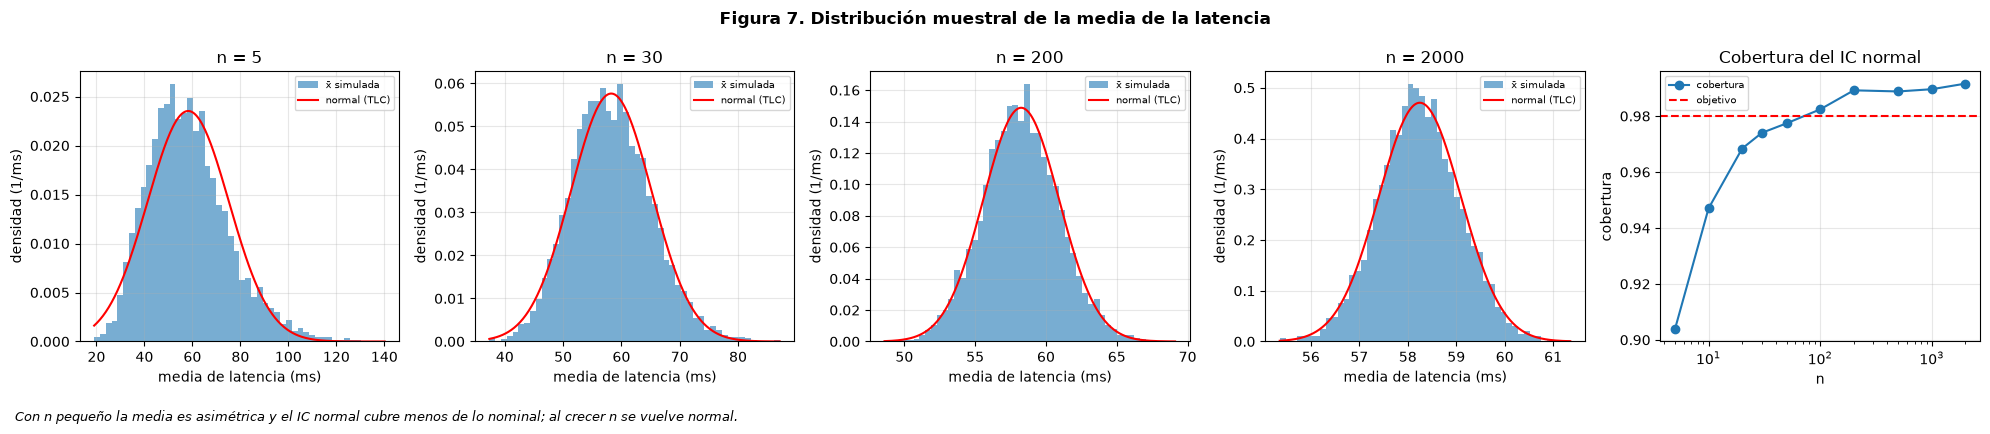

In [33]:
fig, ejes = plt.subplots(1, 5, figsize=(20, 4))
for ax, n in zip(ejes, [5, 30, 200, 2000]):
    ax.hist(medias_n[n], bins=50, density=True, alpha=0.6, label="x̄ simulada")
    x = np.linspace(medias_n[n].min(), medias_n[n].max(), 200)
    ax.plot(x, stats.norm.pdf(x, mu_pob, sigma_pob / np.sqrt(n)), "r", label="normal (TLC)")
    ax.set(title=f"n = {n}", xlabel="media de latencia (ms)", ylabel="densidad (1/ms)")
    ax.legend(fontsize=7)
ejes[4].semilogx(rejilla_n, coberturas, "o-", label="cobertura")
ejes[4].axhline(NIVEL - 0.01, color="red", ls="--", label="objetivo")
ejes[4].set(title="Cobertura del IC normal", xlabel="n", ylabel="cobertura")
ejes[4].legend(fontsize=7)
guardar_figura(fig, 7, "Distribución muestral de la media de la latencia",
               "Con n pequeño la media es asimétrica y el IC normal cubre menos de lo nominal; al crecer n se vuelve normal.")

## F2 — IC para la latencia media
El IC t clásico supone **observaciones independientes**. Pero solicitudes consecutivas comparten la cola: si una
espera mucho, la siguiente también (autocorrelación positiva) y el IC clásico queda demasiado estrecho.
**Corrección: medias por lotes.** Se divide la serie (en orden de llegada) en 30 lotes contiguos; las medias de
lotes largos son casi independientes, y se aplica el IC t a esas 30 medias.

In [34]:
lat = estable.sort_values("t_llegada_s")["latencia_ms"].to_numpy()
print(f"Autocorrelación de rezago 1: {np.corrcoef(lat[:-1], lat[1:])[0, 1]:.3f}")
m, inf_cl, sup_cl = ic_media(lat)
mostrar_ic("Latencia media (ms)", m, inf_cl, sup_cl, "t clásico")
medias_lotes = np.array([lote.mean() for lote in np.array_split(lat, 30)])
_, inf_l, sup_l = ic_media(medias_lotes)
mostrar_ic("Latencia media (ms)", m, inf_l, sup_l, "medias por lotes, 30 lotes")
print(f"El IC corregido es {(sup_l - inf_l) / (sup_cl - inf_cl):.2f} veces más ancho")

Autocorrelación de rezago 1: 0.066
Latencia media (ms): 58.2478  IC 99% [57.2591, 59.2364]  (t clásico)
Latencia media (ms): 58.2478  IC 99% [56.8781, 59.6177]  (medias por lotes, 30 lotes)
El IC corregido es 1.39 veces más ancho


## F3 — Versión B vs versión A
Diferencias B − A en (i) media de G no caché, (ii) P(intentos > 1), (iii) P(L > τ). Como se reportan las tres a la
vez, se usa **Bonferroni**: cada IC al nivel $1-\alpha/3$, para que las tres sean correctas a la vez con
probabilidad ≥ 1 − α. Primero se verifica que la asignación aleatoria dejó grupos comparables.

In [35]:
A, B = estable[estable["version"] == "A"], estable[estable["version"] == "B"]
print("Comparabilidad (medias A vs B):")
display(pd.DataFrame({"A": [A["tam_kb"].mean(), A["cache_hit"].mean(), A["red_ms"].mean(), len(A)],
                      "B": [B["tam_kb"].mean(), B["cache_hit"].mean(), B["red_ms"].mean(), len(B)]},
                     index=["tamaño medio (KB)", "P(caché)", "red media (ms)", "n"]))
print(f"Prueba KS de tamaños A vs B: p = {stats.ks_2samp(A['tam_kb'], B['tam_kb']).pvalue:.3f}")

z_bonf = stats.norm.ppf(1 - ALPHA / 6)
gA, gB = A.loc[A["cache_hit"] == 0, "gpu_ms"], B.loc[B["cache_hit"] == 0, "gpu_ms"]
dif_g = gB.mean() - gA.mean()
semi_g = z_bonf * np.sqrt(gA.var() / len(gA) + gB.var() / len(gB))
resultados_f3 = {
    "(i) E[G no caché] B − A (ms)": (dif_g, dif_g - semi_g, dif_g + semi_g),
    "(ii) P(intentos > 1) B − A": ic_dif_prop((B["intentos"] > 1).sum(), len(B), (A["intentos"] > 1).sum(), len(A), z_bonf),
    "(iii) P(L > τ) B − A": ic_dif_prop((B["latencia_ms"] > TAU_MS).sum(), len(B), (A["latencia_ms"] > TAU_MS).sum(), len(A), z_bonf),
}
tabla_f3 = pd.DataFrame(resultados_f3, index=["diferencia", "inf", "sup"]).T
tabla_f3["veredicto"] = np.where(tabla_f3["sup"] < 0, "B mejor", np.where(tabla_f3["inf"] > 0, "B peor", "sin diferencia"))
print(f"IC conjuntos al {NIVEL:.0%} (Bonferroni, cada uno al {1 - ALPHA/3:.4f}):")
display(tabla_f3)

mejora, empeora = (tabla_f3["veredicto"] == "B mejor").sum(), (tabla_f3["veredicto"] == "B peor").sum()
print("Decisión:", "adoptar B" if mejora and not empeora else "no adoptar B" if empeora and not mejora
      else "compromiso: B mejora en unas métricas y empeora en otras" if mejora else "no hay evidencia para preferir B")

Comparabilidad (medias A vs B):


,A,B
tamaño medio (KB),236.8822,244.1933
P(caché),0.3274,0.3040
red media (ms),23.3391,23.3826
n,4951.0000,4813.0000


Prueba KS de tamaños A vs B: p = 0.053
IC conjuntos al 99% (Bonferroni, cada uno al 0.9967):


,diferencia,inf,sup,veredicto
(i) E[G no caché] B − A (ms),-3.5778,-5.9404,-1.2152,B mejor
(ii) P(intentos > 1) B − A,-0.0074,-0.0282,0.0134,sin diferencia
(iii) P(L > τ) B − A,-0.0005,-0.0038,0.0027,sin diferencia


Decisión: adoptar B


**Regla de decisión:** se adopta B si mejora en al menos una métrica y no empeora en ninguna.

## F4 — Wald vs Wilson para una proporción
Wald: $\hat p\pm z\sqrt{\hat p(1-\hat p)/n}$. Wilson: ver `ic_wilson`. Para cada (n, p) se simulan $10^4$ muestras
y se cuenta cuántos IC contienen el p verdadero.

Wald                      Wilson                     
n       20     50     100    500    20     50     100    500
p                                                           
0.01  0.181  0.386  0.634  0.961  0.982  0.989  0.978  0.988
0.03  0.456  0.779  0.950  0.985  0.979  0.982  0.988  0.988
0.05  0.650  0.926  0.965  0.982  0.982  0.989  0.988  0.991
0.10  0.879  0.964  0.975  0.987  0.989  0.992  0.989  0.990
0.30  0.956  0.979  0.988  0.988  0.994  0.992  0.990  0.991
0.50  0.959  0.985  0.989  0.988  0.987  0.992  0.989  0.988

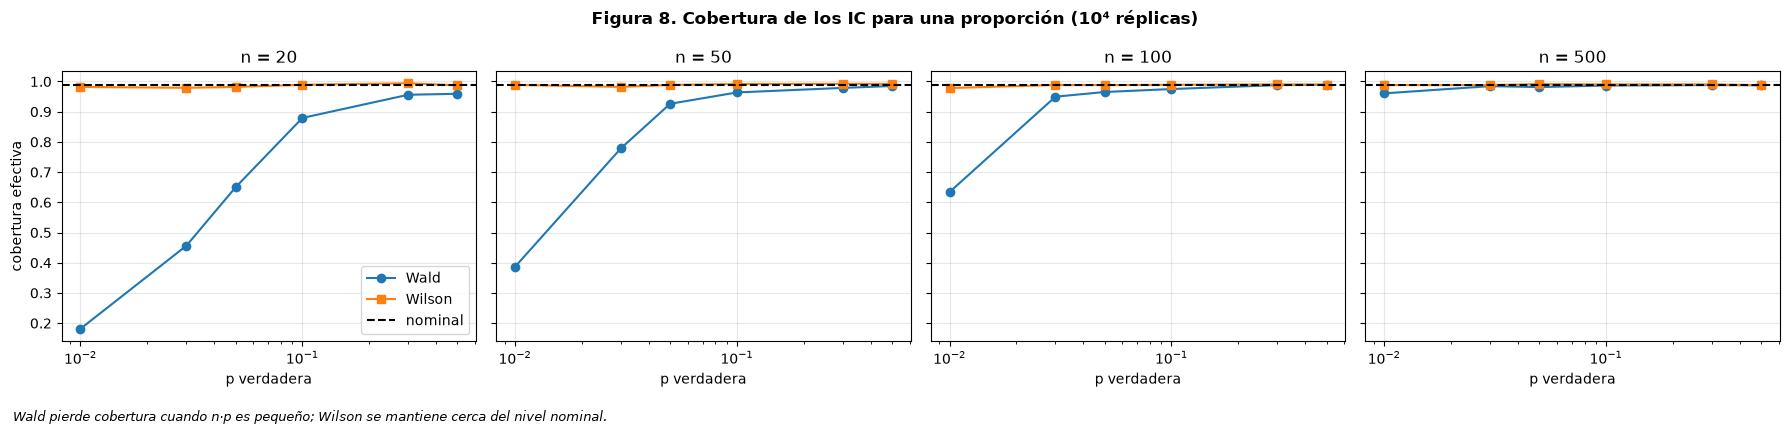

In [36]:
filas_f4 = []
for n in [20, 50, 100, 500]:
    for p in [0.01, 0.03, 0.05, 0.1, 0.3, 0.5]:
        x = rng.binomial(n, p, 10000)
        p_hat = x / n
        semi_wald = Z * np.sqrt(p_hat * (1 - p_hat) / n)
        _, w_inf, w_sup = ic_wilson(x, n)
        filas_f4.append([n, p, np.mean(np.abs(p_hat - p) <= semi_wald), np.mean((w_inf <= p) & (p <= w_sup))])
tabla_f4 = pd.DataFrame(filas_f4, columns=["n", "p", "Wald", "Wilson"])
display(tabla_f4.pivot(index="p", columns="n", values=["Wald", "Wilson"]).round(3))

fig, ejes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (n, g) in zip(ejes, tabla_f4.groupby("n")):
    ax.plot(g["p"], g["Wald"], "o-", label="Wald")
    ax.plot(g["p"], g["Wilson"], "s-", label="Wilson")
    ax.axhline(NIVEL, color="k", ls="--", label="nominal")
    ax.set(title=f"n = {n}", xlabel="p verdadera", xscale="log")
ejes[0].set_ylabel("cobertura efectiva")
ejes[0].legend()
guardar_figura(fig, 8, "Cobertura de los IC para una proporción (10⁴ réplicas)",
               "Wald pierde cobertura cuando n·p es pequeño; Wilson se mantiene cerca del nivel nominal.")

## F5 — Tamaño de muestra para semiancho ≤ 1 ms en F3(i)
$z\sqrt{(\sigma_A^2+\sigma_B^2)/n}\le1\ \Rightarrow\ n\ge z^2(\sigma_A^2+\sigma_B^2)/1^2$ (por versión, no cacheadas),
con el z de Bonferroni usado en F3.

In [37]:
n_f5 = int(np.ceil(z_bonf**2 * (gA.var() + gB.var()) / 1**2))
print(f"n necesario por versión (no cacheadas): {n_f5}")
semis = [z_bonf * np.sqrt(rng.choice(gA, n_f5).var() / n_f5 + rng.choice(gB, n_f5).var() / n_f5) for _ in range(500)]
print(f"Simulación (500 réplicas): semiancho medio = {np.mean(semis):.3f} ms")

n necesario por versión (no cacheadas): 18639
Simulación (500 réplicas): semiancho medio = 1.000 ms


# Parte G — Simulación y decisión de capacidad

## G1 — Simulador propio
Modelos usados (todos ajustados antes):
- llegadas: proceso de Poisson de tasa λ (B1);
- tamaño de la imagen: tomado al azar de los tamaños observados;
- caché: probabilidad según la clase de tamaño (D1);
- G: Gamma con media $\beta_0+\beta_1\,\text{tam}$ y forma k (D3);
- red: tomada al azar de los tiempos de red observados (remuestreo: no impone ninguna forma; ver C3).

**Cola FIFO con c GPUs:** se guarda en una lista a qué hora queda libre cada GPU. Cada solicitud (en orden de
llegada) empieza cuando llega o cuando se libera la primera GPU, lo que ocurra después.
$L=\text{red}+\text{espera}+G$. Se descartan los primeros 200 s (el sistema arranca vacío).

In [38]:
def armar_modelo(datos, tasa):
    clase = np.searchsorted([T1_KB, T2_KB], datos["tam_kb"], side="right")      # 0, 1, 2
    p_cache = [datos["cache_hit"][clase == i].mean() for i in range(3)]
    nc = datos[datos["cache_hit"] == 0]
    beta = minimos_cuadrados(nc["tam_kb"].to_numpy(), nc["gpu_ms"].to_numpy())[0]
    for _ in range(20):                                                       # MCP con pesos 1/μ² (D3)
        beta, _, phi = minimos_cuadrados(nc["tam_kb"].to_numpy(), nc["gpu_ms"].to_numpy(),
                                         1 / (beta[0] + beta[1] * nc["tam_kb"].to_numpy())**2)
    return {"tasa": tasa, "tam": datos["tam_kb"].to_numpy(), "red": datos["red_ms"].to_numpy(),
            "p_cache": np.array(p_cache), "beta": beta, "k": 1 / phi,
            "carga_por_seg": (1 - datos["cache_hit"].mean()) * nc["gpu_ms"].mean() / 1000}


def simular(modelo, c, duracion=1200, calentamiento=200):
    """Una corrida del sistema con c GPUs. Devuelve las latencias (ms) después del calentamiento."""
    total = duracion + calentamiento
    n = rng.poisson(modelo["tasa"] * total)
    llegada = np.sort(rng.uniform(0, total, n))              # Poisson: dado n, instantes uniformes
    tam = rng.choice(modelo["tam"], n)
    clase = np.searchsorted([T1_KB, T2_KB], tam, side="right")
    cache = rng.random(n) < modelo["p_cache"][clase]
    media_g = np.maximum(modelo["beta"][0] + modelo["beta"][1] * tam, 1.0)
    g = np.where(cache, 0.0, rng.gamma(modelo["k"], media_g / modelo["k"]))
    red = rng.choice(modelo["red"], n)

    libre = [0.0] * c                                       # hora (s) en que queda libre cada GPU
    espera = np.zeros(n)
    for i in np.flatnonzero(~cache):                        # solo las no cacheadas usan GPU, en orden de llegada
        j = libre.index(min(libre))                         # la GPU que se libera primero
        inicio = max(llegada[i], libre[j])
        espera[i] = (inicio - llegada[i]) * 1000
        libre[j] = inicio + g[i] / 1000
    latencia = red + espera + g
    return latencia[llegada >= calentamiento]


modelo = armar_modelo(estable, lam)
print(f"Modelo: λ = {lam:.2f}/s, P(caché|clase) = {np.round(modelo['p_cache'], 3)}, "
      f"β = {np.round(modelo['beta'], 4)}, k = {modelo['k']:.2f}")

Modelo: λ = 21.89/s, P(caché|clase) = [0.508 0.301 0.139], β = [15.779   0.1174], k = 3.99


**Validación con c = 2 y la tasa actual:** cuantiles y P(L > τ) de 20 corridas vs datos reales.

In [39]:
cuantiles = [0.5, 0.9, 0.95, 0.99]
corridas = [simular(modelo, C0) for _ in range(20)]
sim_q = np.array([np.quantile(L, cuantiles) for L in corridas])
sim_p = np.array([np.mean(L > TAU_MS) for L in corridas])
validacion = pd.DataFrame({
    "datos": list(np.quantile(lat, cuantiles)) + [np.mean(lat > TAU_MS)],
    "simulación": list(sim_q.mean(axis=0)) + [sim_p.mean()],
}, index=["p50 (ms)", "p90 (ms)", "p95 (ms)", "p99 (ms)", "P(L > τ)"])
validacion["diferencia %"] = 100 * (validacion["simulación"] - validacion["datos"]) / validacion["datos"]
display(validacion)
mostrar_ic("P(L > τ) datos", *ic_wilson(np.sum(lat > TAU_MS), len(lat)), "Wilson")
mostrar_ic("P(L > τ) simulación", *ic_media(sim_p), "t sobre 20 corridas")

,datos,simulación,diferencia %
p50 (ms),50.4300,50.3929,-0.0736
p90 (ms),107.7450,108.5011,0.7017
p95 (ms),131.6170,132.4335,0.6204
p99 (ms),185.2581,189.5119,2.2961
P(L > τ),0.0030,0.0033,10.3375


P(L > τ) datos: 0.0030  IC 99% [0.0018, 0.0048]  (Wilson)
P(L > τ) simulación: 0.0033  IC 99% [0.0030, 0.0036]  (t sobre 20 corridas)


**Lectura:** si las diferencias son pequeñas y el IC de los datos contiene el valor simulado, el simulador
reproduce el sistema. La mayor discrepancia suele estar en la cola (p99, P(L > τ)): hay pocas violaciones en los
datos (IC ancho) y el modelo ignora efectos como ráfagas o reintentos que vuelven a la cola.

## G2 — Tasa × g: ¿cuántas GPUs?
**Carga ofrecida** $a=\lambda g(1-p_c)E[G\mid\text{no caché}]$ = GPUs ocupadas en promedio. Con c GPUs la
utilización es $\rho=a/c$; si $\rho\ge1$ la cola crece sin límite (inestable).

**Réplicas:** dentro de una corrida las latencias están correlacionadas (comparten la cola), así que cada corrida
aporta un solo valor $\hat P_r$. Las 20 corridas son independientes (números aleatorios distintos, cola vacía al
inicio), así que el IC t sobre ellas es válido. 20 corridas dan un IC mucho más angosto que ε.

Se elige el menor c cuyo IC completo queda por debajo de ε.

Tasa proyectada = 41.59/s, carga ofrecida = 1.32 GPUs ocupadas en promedio


IC al 99%, método t sobre 20 réplicas independientes:


,ρ,P(L>τ),inf,sup
c,,,,
1,1.3224,0.6843,0.6832,0.6855
2,0.6612,0.0223,0.0208,0.0238


c* = 2 GPUs


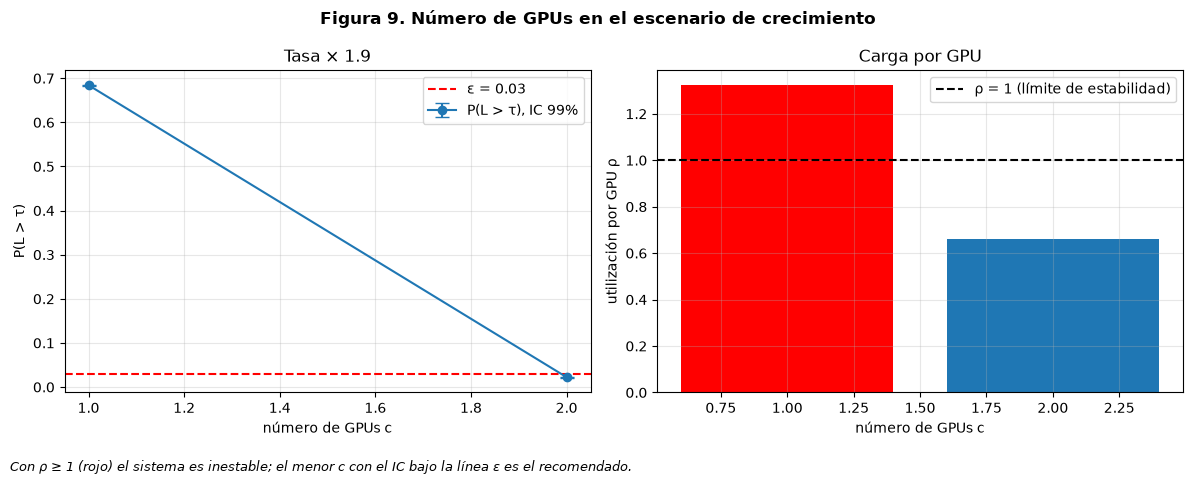

In [40]:
modelo_g = dict(modelo, tasa=lam * G_CREC)
carga = modelo_g["tasa"] * modelo["carga_por_seg"]
print(f"Tasa proyectada = {modelo_g['tasa']:.2f}/s, carga ofrecida = {carga:.2f} GPUs ocupadas en promedio")

filas_g2, c_estrella = [], None
for c in range(1, 8):
    p_r = np.array([np.mean(simular(modelo_g, c) > TAU_MS) for _ in range(20)])
    est, inf, sup = ic_media(p_r)
    filas_g2.append([c, carga / c, est, inf, sup])
    if sup <= EPSILON:
        c_estrella = c
        break
tabla_g2 = pd.DataFrame(filas_g2, columns=["c", "ρ", "P(L>τ)", "inf", "sup"]).set_index("c")
print(f"IC al {NIVEL:.0%}, método t sobre 20 réplicas independientes:")
display(tabla_g2)
print(f"c* = {c_estrella} GPUs")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].errorbar(tabla_g2.index, tabla_g2["P(L>τ)"], yerr=[tabla_g2["P(L>τ)"] - tabla_g2["inf"],
                 tabla_g2["sup"] - tabla_g2["P(L>τ)"]], fmt="o-", capsize=5, label=f"P(L > τ), IC {NIVEL:.0%}")
ejes[0].axhline(EPSILON, color="red", ls="--", label=f"ε = {EPSILON}")
ejes[0].set(xlabel="número de GPUs c", ylabel="P(L > τ)", title=f"Tasa × {G_CREC}")
ejes[0].legend()
ejes[1].bar(tabla_g2.index, tabla_g2["ρ"], color=["red" if r >= 1 else "C0" for r in tabla_g2["ρ"]])
ejes[1].axhline(1, color="k", ls="--", label="ρ = 1 (límite de estabilidad)")
ejes[1].set(xlabel="número de GPUs c", ylabel="utilización por GPU ρ", title="Carga por GPU")
ejes[1].legend()
guardar_figura(fig, 9, "Número de GPUs en el escenario de crecimiento",
               "Con ρ ≥ 1 (rojo) el sistema es inestable; el menor c con el IC bajo la línea ε es el recomendado.")

## G3 — Robustez de c* frente a la incertidumbre de los parámetros
Se repite 30 veces: (1) se remuestrean con reemplazo las solicitudes del régimen estable (bootstrap) y se toma
$\lambda_b=N_b/T$ con $N_b\sim\text{Poisson}(n)$; (2) se reajusta todo el modelo; (3) se busca el menor c con
$\hat P(L>\tau)\le\varepsilon$. La distribución de esos c* mide la robustez.

**Modelo analítico de contraste: M/M/c (Erlang C).** Supone servicio exponencial con media $E[G]$. La probabilidad
de esperar es $C(c,a)$ y la espera, dado que se espera, es Exp($c\mu-\lambda$). Se aproxima
$P(L>\tau)\approx p_c\,P(\text{red}>\tau)+(1-p_c)\,P(\text{red}+W+S>\tau)$ por Montecarlo sobre red, W y S.

In [41]:
c_boot = []
for _ in range(30):
    remuestra = estable.iloc[rng.integers(0, len(estable), len(estable))]
    modelo_b = armar_modelo(remuestra, rng.poisson(n_lleg) / T_EST * G_CREC)
    c = int(modelo_b["tasa"] * modelo_b["carga_por_seg"]) + 1               # menor c estable
    while np.mean([np.mean(simular(modelo_b, c) > TAU_MS) for _ in range(5)]) > EPSILON:
        c += 1
    c_boot.append(c)
print("Distribución de c* bajo incertidumbre:", pd.Series(c_boot).value_counts(normalize=True).sort_index().to_dict())


def p_violacion_mmc(c, m=50000):
    lam_gpu = lam * G_CREC * (1 - p_c)                     # solicitudes por segundo que usan GPU
    mu = 1000 / mu_c                                        # capacidad de una GPU (sol/s)
    a = lam_gpu / mu
    if a >= c:
        return 1.0
    suma = sum(a**k / math.factorial(k) for k in range(c))
    ultimo = a**c / math.factorial(c) / (1 - a / c)
    prob_espera = ultimo / (suma + ultimo)                  # fórmula de Erlang C
    espera = np.where(rng.random(m) < prob_espera, rng.exponential(1 / (c * mu - lam_gpu), m), 0) * 1000
    servicio = rng.exponential(mu_c, m)
    red_m = rng.choice(red, m)
    return p_c * np.mean(red_m > TAU_MS) + (1 - p_c) * np.mean(red_m + espera + servicio > TAU_MS)

c_mmc = next(c for c in range(1, 20) if p_violacion_mmc(c) <= EPSILON)
print(f"c* simulación = {c_estrella} | c* M/M/c = {c_mmc} "
      f"(CV² del servicio real = {g_nc.var() / g_nc.mean()**2:.2f}; en M/M/c es 1)")

Distribución de c* bajo incertidumbre: {2: 0.9666666666666667, 3: 0.03333333333333333}
c* simulación = 2 | c* M/M/c = 3 (CV² del servicio real = 0.50; en M/M/c es 1)


**Lectura:** si el CV² real es menor que 1, el servicio es menos variable que en M/M/c, así que M/M/c sobrestima las
esperas y puede pedir más GPUs. Además M/M/c ignora que G y la caché dependen del tamaño.

## F6 — Validación con `solicitudes_validacion.csv`
(Se presenta aquí porque usa el simulador.) Se aplican la misma auditoría (A1) y el mismo criterio de régimen
estable (A2), y se comparan los parámetros
principales con los originales; luego se recalcula c* con el modelo de la nueva ventana.

In [42]:
ruta_val = DIR_DATOS / "solicitudes_validacion.csv"
def p_dos_prop(a, b):
    """p-valor χ² para comparar dos proporciones (a y b son vectores de 0/1)."""
    return stats.chi2_contingency([[np.sum(a), len(a) - np.sum(a)], [np.sum(b), len(b) - np.sum(b)]])[1]


if ruta_val.exists():
    llegadas_v, limpio_v, _ = auditar(pd.read_csv(ruta_val))
    ini_v, fin_v = tramo_estable(segmentar(llegadas_v, limpio_v))     # mismo criterio de régimen que A2
    T_v = fin_v - ini_v
    print(f"Validación: régimen estable [{ini_v:.0f}, {fin_v:.0f}) s")
    val = limpio_v[limpio_v["t_llegada_s"].between(ini_v, fin_v, inclusive="left")]
    nc_v = val[val["cache_hit"] == 0]
    lam_v = llegadas_v["t_llegada_s"].between(ini_v, fin_v, inclusive="left").sum() / T_v
    filas_f6 = [
        ["λ (sol/s)", lam, lam_v, 2 * stats.norm.sf(abs(lam_v - lam) / np.sqrt(lam / T_EST + lam_v / T_v))],
        ["P(caché)", p_c, val["cache_hit"].mean(), p_dos_prop(estable["cache_hit"] == 1, val["cache_hit"] == 1)],
        ["q (EMV)", q_hat, (val["intentos"] - val["exito"]).sum() / val["intentos"].sum(),
         stats.chi2_contingency([[F, I_total - F], [(val["intentos"] - val["exito"]).sum(), val["exito"].sum()]])[1]],
        ["E[G no caché] (ms)", g_nc.mean(), nc_v["gpu_ms"].mean(), stats.ttest_ind(g_nc, nc_v["gpu_ms"], equal_var=False).pvalue],
        ["E[red] (ms)", red.mean(), val["red_ms"].mean(), stats.ttest_ind(red, val["red_ms"], equal_var=False).pvalue],
        ["P(L > τ)", np.mean(lat > TAU_MS), np.mean(val["latencia_ms"] > TAU_MS),
         p_dos_prop(lat > TAU_MS, val["latencia_ms"] > TAU_MS)],
    ]
    tabla_f6 = pd.DataFrame(filas_f6, columns=["parámetro", "original", "validación", "p-valor"]).set_index("parámetro")
    tabla_f6["cambio %"] = 100 * (tabla_f6["validación"] - tabla_f6["original"]) / tabla_f6["original"]
    tabla_f6["¿cambió?"] = tabla_f6["p-valor"] < ALPHA
    display(tabla_f6)

    modelo_v = armar_modelo(val, lam_v * G_CREC)
    c_v = int(modelo_v["tasa"] * modelo_v["carga_por_seg"]) + 1
    while ic_media([np.mean(simular(modelo_v, c_v) > TAU_MS) for _ in range(20)])[2] > EPSILON:
        c_v += 1
    print(f"c* con los datos de validación = {c_v} (original: {c_estrella})")
else:
    print("Aún no está solicitudes_validacion.csv: F6 se ejecutará cuando se copie a", DIR_DATOS)

Validación: régimen estable [0, 1200) s


,original,validación,p-valor,cambio %,¿cambió?
parámetro,,,,,
λ (sol/s),21.8889,21.4717,1.0577e-01,-1.9061,False
P(caché),0.3159,0.3198,4.8029e-01,1.2611,False
q (EMV),0.1440,0.1857,1.4542e-23,28.9108,True
E[G no caché] (ms),46.4783,46.3759,8.2899e-01,-0.2203,False
E[red] (ms),23.3606,23.3527,8.5367e-01,-0.0337,False
P(L > τ),0.0030,0.0031,8.9670e-01,5.2649,False


c* con los datos de validación = 2 (original: 2)


## G4 — Memorando ejecutivo
Se entrega aparte (`memo/`, una página en PDF) con las cifras de este notebook.